In [10]:
%pip install numpy
%pip install matplotlib
%pip install pandas
%pip install scipy
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [11]:
file_path_D1 = r"Pruebas_DELFT_20260929.txt"
file_path_D2 = r"Pruebas_DELFT_20261002.txt"

columns = [
    "point_id",
    "date",
    "time",
    "easting",
    "northing",
    "ellipsoidal_height",
    "geoid_separation",
    "cq_3d",
]

def load_gps(file_path):
    gps = pd.read_csv(
        file_path,
        sep=r"\s+",
        skiprows=1,          # skip the descriptive header
        names=columns,
        dtype={
            "point_id": "string",
            "date": "string",
            "time": "string",
            "easting": "float64",
            "northing": "float64",
            "ellipsoidal_height": "float64",
            "geoid_separation": "float64",
            "cq_3d": "float64",
        },
    )

    gps["datetime"] = pd.to_datetime(
        gps["date"] + " " + gps["time"],
        format="%m/%d/%Y %H:%M:%S",
    )
    gps["datetime"] = gps["datetime"] - pd.Timedelta(hours=1)
    gps = gps.drop(columns=["date", "time"])

    # Determining actual elevations
    gps["elevation"] = gps["ellipsoidal_height"] - gps["geoid_separation"]
    return gps

gps_D1 = load_gps(file_path_D1)
gps_D2 = load_gps(file_path_D2)


display(gps_D1.head())
display(gps_D2.head())

,point_id,easting,northing,ellipsoidal_height,geoid_separation,cq_3d,datetime,elevation
0,GPS0001,806688.1680,2.343461e+06,-15.2602,-13.9310,0.0159,2026-09-29 11:18:19,-1.3292
1,GPS0002,806687.4266,2.343459e+06,-15.2558,-13.9309,0.0159,2026-09-29 11:18:40,-1.3249
2,GPS0003,806697.2479,2.343461e+06,-15.3033,-13.9310,0.0177,2026-09-29 11:19:18,-1.3723
3,GPS0004,806687.4149,2.343452e+06,-15.3480,-13.9308,0.0156,2026-09-29 11:19:56,-1.4172
4,GPS0005,806680.4073,2.343383e+06,-14.3263,-13.9294,0.0210,2026-09-29 11:22:42,-0.3969


,point_id,easting,northing,ellipsoidal_height,geoid_separation,cq_3d,datetime,elevation
0,RTCM-Ref0017,806520.1897,2.343199e+06,-2.3498,-13.9267,NaN,2026-10-02 09:52:57,11.5769
1,GPS_Auto_000001,806503.2658,2.343120e+06,-14.1150,-13.9252,0.0171,2026-10-02 09:54:30,-0.1898
2,GPS_Auto_000002,806503.4395,2.343120e+06,-14.1546,-13.9252,0.0157,2026-10-02 09:54:31,-0.2294
3,GPS_Auto_000003,806503.7183,2.343120e+06,-14.0603,-13.9252,0.0158,2026-10-02 09:54:32,-0.1351
4,GPS_Auto_000004,806504.1683,2.343120e+06,-14.0468,-13.9252,0.0155,2026-10-02 09:54:33,-0.1216


In [12]:
def add_trajectory_and_speed(gps):
    gps = gps.copy()

        # Extract the label from point_id ("GPS_Auto_000001" -> "GPS_Auto", "GPS0001" -> "GPS")
    gps["trajectory"] = gps["point_id"].str.extract(
        r"^([A-Za-z]+(?:_[A-Za-z]+)*)",
        expand=False,
    )
    # Day 2 calls the boat track GPS_Auto; give it the same label as day 1
    gps["trajectory"] = gps["trajectory"].replace({"GPS_Auto": "TEST"})

    # Calculate horizontal speed within each trajectory
    ordered_gps = gps.sort_values(["trajectory", "datetime"])

    delta_easting = ordered_gps.groupby("trajectory")["easting"].diff()
    delta_northing = ordered_gps.groupby("trajectory")["northing"].diff()

    delta_time = (
        ordered_gps.groupby("trajectory")["datetime"]
        .diff()
        .dt.total_seconds()
    )

    distance = np.hypot(delta_easting, delta_northing)

    # Speed in metres per second
    speed_m_s = distance / delta_time.where(delta_time > 0)

    # Add the results to the original DataFrame order
    gps["speed_m_s"] = speed_m_s.reindex(gps.index)
    gps["speed_km_h"] = gps["speed_m_s"] * 3.6
    return gps


gps_D1 = add_trajectory_and_speed(gps_D1)
gps_D2 = add_trajectory_and_speed(gps_D2)

test_D1 = gps_D1[gps_D1["trajectory"] == "TEST"].sort_values("datetime")
test_D2 = gps_D2[gps_D2["trajectory"] == "TEST"].sort_values("datetime")

gps_points_D1 = gps_D1[gps_D1["trajectory"] == "GPS"].sort_values("datetime")
gps_points_D2 = gps_D2[gps_D2["trajectory"] == "GPS"].sort_values("datetime")

show = ["point_id", "trajectory", "datetime", "speed_m_s", "speed_km_h"]
display(gps_D1[show])
display(gps_D2[show])

# Both days in one table: the functions select the right day by date and time
gps = pd.concat([gps_D1, gps_D2], ignore_index=True)
gps_points = pd.concat([gps_points_D1, gps_points_D2], ignore_index=True)

,point_id,trajectory,datetime,speed_m_s,speed_km_h
0,GPS0001,GPS,2026-09-29 11:18:19,NaN,NaN
1,GPS0002,GPS,2026-09-29 11:18:40,0.074992,0.269972
2,GPS0003,GPS,2026-09-29 11:19:18,0.264426,0.951933
3,GPS0004,GPS,2026-09-29 11:19:56,0.362235,1.304045
4,GPS0005,GPS,2026-09-29 11:22:42,0.417235,1.502046
...,...,...,...,...,...
12898,TEST012676,TEST,2026-09-29 11:09:01,0.618595,2.226943
12899,TEST012677,TEST,2026-09-29 11:09:02,0.770201,2.772725
12900,TEST012678,TEST,2026-09-29 11:09:03,0.628138,2.261297
12901,TEST012679,TEST,2026-09-29 11:09:04,0.256624,0.923846


,point_id,trajectory,datetime,speed_m_s,speed_km_h
0,RTCM-Ref0017,RTCM,2026-10-02 09:52:57,NaN,NaN
1,GPS_Auto_000001,TEST,2026-10-02 09:54:30,NaN,NaN
2,GPS_Auto_000002,TEST,2026-10-02 09:54:31,0.328568,1.182845
3,GPS_Auto_000003,TEST,2026-10-02 09:54:32,0.368721,1.327395
4,GPS_Auto_000004,TEST,2026-10-02 09:54:33,0.475849,1.713056
...,...,...,...,...,...
6143,GPS0001,GPS,2026-10-02 11:43:30,NaN,NaN
6144,GPS0002,GPS,2026-10-02 11:44:11,0.021656,0.077960
6145,GPS0003,GPS,2026-10-02 11:44:36,0.018149,0.065336
6146,GPS0004,GPS,2026-10-02 11:45:17,0.076163,0.274187


In [13]:
cols = [
    "burst",        # Burst counter
    "ensemble",     # Ensemble counter (1-65536)
    "w",            # Velocity Beam1|X|East (m/s) orginally u renamed to w to reflect vertical velocities
    "u",            # Velocity Beam2|Y|North (m/s) originally v now renamed to u to reflect crossh shore velocities
    "v",            # Velocity Beam3|Z|Up (m/s) orginally w now renamed to v to reflect alongshore velocities
    "amp1",         # Amplitude Beam1 (counts)
    "amp2",         # Amplitude Beam2 (counts)
    "amp3",         # Amplitude Beam3 (counts)
    "snr1",         # SNR Beam1 (dB)
    "snr2",         # SNR Beam2 (dB)
    "snr3",         # SNR Beam3 (dB)
    "corr1",        # Correlation Beam1 (%)
    "corr2",        # Correlation Beam2 (%)
    "corr3",        # Correlation Beam3 (%)
    "pressure",     # Pressure (dbar)
    "analog1",      # Analog input 1
    "analog2",      # Analog input 2
    "checksum",     # Checksum (1 = failed)
]

df_SSC01 = pd.read_csv("SSC01.dat", sep=r"\s+", header=None, names=cols)
df_SSC02L = pd.read_csv("SSC02A.dat", sep=r"\s+", header=None, names=cols)
df_SSC02H = pd.read_csv("SSC02B.dat", sep=r"\s+", header=None, names=cols)

In [14]:
df_SSC01["t"] = df_SSC01.index / 16                     #Data from first field compain on 29 september
start = pd.Timestamp("2026-09-29 06:00:00")
df_SSC01["time"] = start + pd.to_timedelta(df_SSC01["t"], unit="s")

df_SSC02L["t"] = df_SSC02L.index / 16.                  #Data from second field compain on 2 oktober from the lowest sensor
start = pd.Timestamp("2026-10-02 06:00:00")
df_SSC02L["time"] = start + pd.to_timedelta(df_SSC02L["t"], unit="s")

df_SSC02H["t"] = df_SSC02H.index / 16                   #Data from second field compain on 2 oktober from the highest sensor
start = pd.Timestamp("2026-10-02 06:00:00")
df_SSC02H["time"] = start + pd.to_timedelta(df_SSC02H["t"], unit="s")

In [15]:
m = pd.read_csv("manoeuvresTimes.csv") #import of the manoeuvres times
manoeuvres = {k: v.split(";") for k, v in zip(m["id"], m["times"])}

# Both days in one table: the functions select the right day by date and time
gps = pd.concat([gps_D1, gps_D2], ignore_index=True)
gps_points = pd.concat([gps_points_D1, gps_points_D2], ignore_index=True)

def select(ids):
    """Accepts one id ("B-11"), a list (["B-11", "B-12"]) or a whole type ("B")."""
    if isinstance(ids, str):
        ids = [ids]
    out = []
    for i in ids:
        if i in manoeuvres:
            out.append(i)
        else:
            matches = [k for k in manoeuvres if k.split("-")[0] == i]
            if not matches:
                raise KeyError(f"Unknown manoeuvre or type: {i}")
            out += matches
    return out

def sources(name, sensor="Both"):
    """Which dataframe(s) to use for a manoeuvre, from its series digit (the 3 in B-31)."""
    if name[-2] in "1234":
        return [(df_SSC01, "", "-")]
    out = []
    if sensor in ("Both", "Low"):
        out.append((df_SSC02L, "Low", "-."))
    if sensor in ("Both", "High"):
        out.append((df_SSC02H, "High", "--"))
    return out

def plot_track(ax, name, c, passes, before, after, norm, colour):
    """GPS track of the boat around one manoeuvre. c is the time of the first pass."""
    start = c - pd.Timedelta(seconds=before)
    end = c + pd.Timedelta(seconds=passes[-1] + after)

    test = gps[gps["datetime"].between(start, end) & (gps["trajectory"] == "TEST")].sort_values("datetime")
    if test.empty:
        print(f"No GPS track around {name} ({c:%Y-%m-%d %H:%M:%S}), not on the map")
        return
    rel_t = (test["datetime"] - c).dt.total_seconds()
    ax.plot(test["easting"], test["northing"], color=colour, lw=1, label=name)
    ax.scatter(test["easting"], test["northing"], c=rel_t, cmap="viridis", norm=norm, s=15, zorder=3)

    # Position of the boat at the moment of each pass, interpolated along the track.
    inside = [p for p in passes if rel_t.min() <= p <= rel_t.max()]
    x, y = np.interp(inside, rel_t, test["easting"]), np.interp(inside, rel_t, test["northing"])
    ax.scatter(x, y, color="red", marker="x", s=100, linewidths=2, zorder=5)
    if inside:                              # name next to the first pass
        ax.annotate(name, (x[0], y[0]), xytext=(8, 8), textcoords="offset points", fontweight="bold")

    # GPS points measured during this manoeuvre get the colour of their time.
    if "gps_points" in globals():
        pts = gps_points[gps_points["datetime"].between(start, end)]
        ax.scatter(pts["easting"], pts["northing"], c=(pts["datetime"] - c).dt.total_seconds(),
                   cmap="viridis", norm=norm, marker="x", s=70, linewidths=1.5, zorder=4)

def plot_overlay(ids, sensor="Both", before=120, after=120, col="analog1", show_map=True):
    show_map = show_map and "gps" in globals()      # no map if the GPS data is not loaded
    if show_map:
        fig, (ax, ax_map) = plt.subplots(1, 2, figsize=(18, 6), layout="constrained",
                                         gridspec_kw={"width_ratios": [1.2, 1]})
        norm = mpl.colors.Normalize(-before, after)  # colour scale of the map: seconds from passage
    else:
        fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")

    days = set()                            # days that appear in this plot

    for name in select(ids):
        t = manoeuvres[name]
        if isinstance(t, str):              # single pass -> list of one
            t = [t]
        offsets = pd.to_timedelta(t)        # time of day of each pass
        passes = [(off - offsets[0]).total_seconds() for off in offsets]   # seconds after the first pass
        colour = None

        for data, suffix, ls in sources(name, sensor):
            times = data["time"].iloc[0].normalize() + offsets
            c = times[0]
            win = data[(data["time"] >= c - pd.Timedelta(seconds=before)) &
                       (data["time"] <= times[-1] + pd.Timedelta(seconds=after))]
            if win.empty:
                print(f"No data around {name}{suffix} ({c:%H:%M:%S}), skipped")
                continue
            rel_t = (win["time"] - c).dt.total_seconds()
            line, = ax.plot(rel_t, win[col], ls=ls, lw=0.8, label=f"{name}{suffix}  ({c:%H:%M:%S})")
            colour = colour or line.get_color()

        if len(t) > 1:                      # F manoeuvres: mark every pass
            for i, x in enumerate(passes, 1):
                ax.axvline(x, color="k", ls="--", lw=0.8)
                ax.text(x, 0.95, f"pass {i}", transform=ax.get_xaxis_transform(),
                        ha="center", fontsize=10, color="red",
                        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="k"))

        if show_map:                        # same manoeuvre on the map, in the same colour
            day = sources(name)[0][0]["time"].iloc[0].normalize()
            days.add(day)
            norm.vmax = max(norm.vmax, passes[-1] + after)
            plot_track(ax_map, name, day + offsets[0], passes, before, after, norm, colour)

    ax.axvline(0, color="k", ls="--", lw=0.8)
    ax.set_xlabel("Time relative to boat passage (s)")
    ax.set_ylabel(col)
    ax.set_title(f"{col}: {before} s before to {after} s after passage")
    ax.grid(True, alpha=0.3)
    ax.legend()

    if show_map:
        if "gps_points" in globals():       # GPS points of the plotted day(s) in grey, as a reference
            ref = gps_points[gps_points["datetime"].dt.normalize().isin(list(days))]
            ax_map.scatter(ref["easting"], ref["northing"], color="0.6", marker="x",
                           s=70, linewidths=1.5, zorder=1, label="GPS points")
        ax_map.scatter([], [], color="red", marker="x", s=100, linewidths=2, label="Boat at passage")
        ax_map.set_aspect("equal", adjustable="datalim")
        ax_map.set_xlabel("Easting [m]")
        ax_map.set_ylabel("Northing [m]")
        ax_map.set_title("GPS track of the boat")
        ax_map.grid(True, alpha=0.3)
        ax_map.legend()
        fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap="viridis"), ax=ax_map,
                     label="Time relative to boat passage (s)")

    plt.show()

#### Plotting manoeuvres with `plot_overlay`
`plot_overlay` plots the sensor signal around one or more boat passages, with time shown relative to the moment of passage. Next to it, the GPS track of the boat over the same period is shown on a map.

```python
plot_overlay("B-21", before=120, after=120, col="w")   # one manoeuvre
plot_overlay(["B-11", "B-12"], col="analog1")          # a few manoeuvres
plot_overlay("B", col="analog1")                       # every B manoeuvre
```
| Argument | What it does | Default |
|---|---|---|
| `before` | Seconds to plot before the manoeuvre | `120` |
| `after` | Seconds to plot after the manoeuvre | `120` |
| `col` | Column to plot, e.g. `"analog1"`, `"u"`, `"v"`, `"w"`, `"pressure"` | `"analog1"` |
| `sensor` | Which sensor to use for the second field day (see below) | `"Both"` |
| `show_map` | Show the GPS map next to the plot | `True` |


The `sensor` option only applies to data from the second field day (2 October).
- `sensor="Both"` → plots both the high and the low sensor
- `sensor="Low"` → plots only the low sensor
- `sensor="High"` → plots only the high sensor

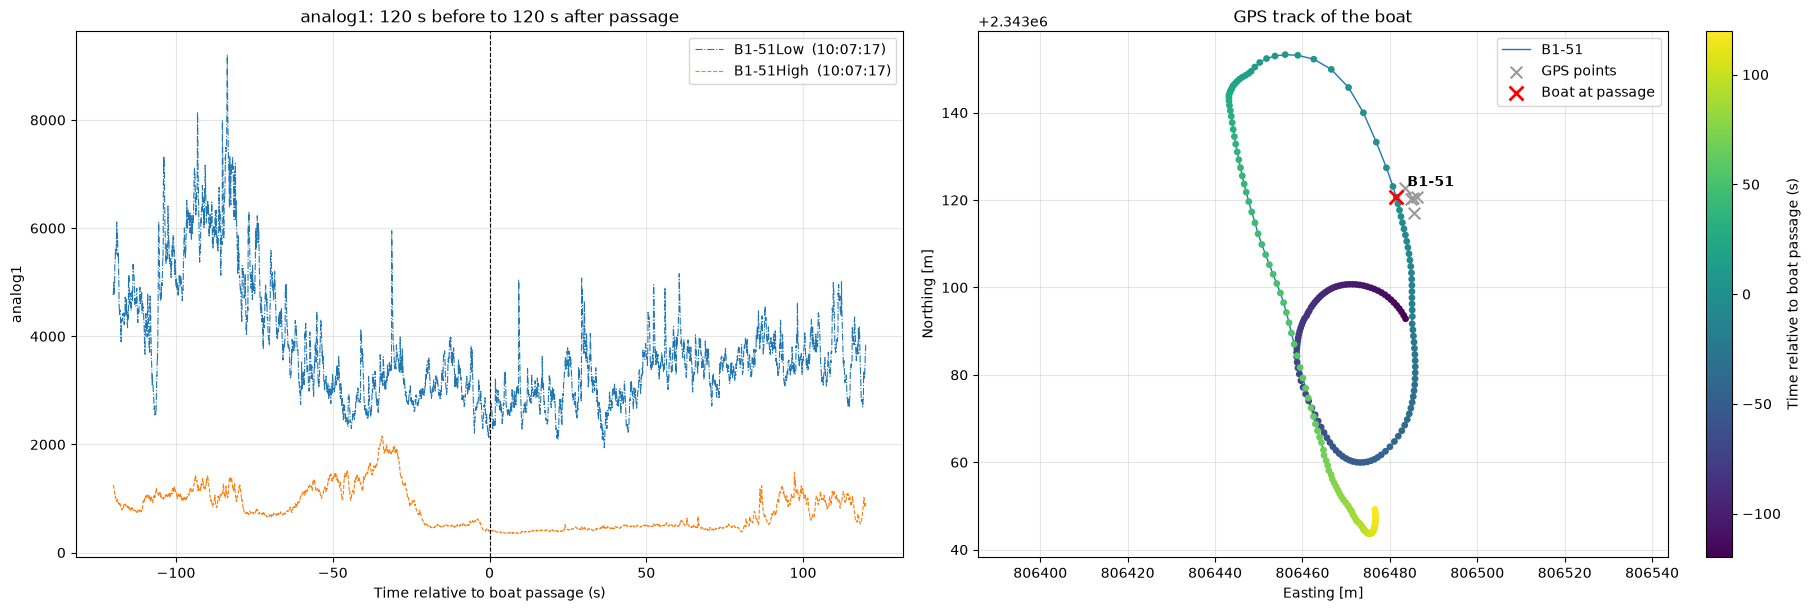

In [16]:
plot_overlay("B1-51", sensor="Both", before = 120, after = 120, col = "analog1")                       # one manoeuvre

#plot_overlay(df, "B-21", before = 1000, after = 1000, col = "v")    
#plot_overlay(df, "B-21", before = 120, after = 120, col = "w")                       # one manoeuvre
                   # one manoeuvre
#plot_overlay(df, ["B-11", "B-12"], col="analog")    # a few
#plot_overlay(df, "B", col="analog1")                 # every B manoeuvre
#plot_overlay(df, "A1")                         # every A1 manoeuvre

#### Relation between `analog1` (OBS) and the velocities: `plot_relation`
`plot_relation` compares the OBS signal with a velocity quantity around one or more manoeuvres. It selects manoeuvres the same way as `plot_overlay` (one id, a list, or a whole type).

```python
plot_relation("B1-51", kind="scatter")                       # analog1 against w
plot_relation("B1-51", kind="lag", x="w_rms", max_lag=60)    # which time lag fits best
plot_relation("B1", kind="lagmap", x="w_rms")                # time lag of every B1 manoeuvre
plot_relation("B1-51", kind="all")                           # every plot below
```

| `kind` | What it shows |
|---|---|
| `"scatter"` | Every sample as a point, coloured by time since the passage, with a straight-line fit and the correlation |
| `"density"` | Where most points lie (useful with many points), the typical `analog1` per range of `x`, and the spread of both signals |
| `"timeseries"` | Both signals in time, and below them the correlation in a moving window |
| `"lag"` | Correlation for every time lag, and the scatter after shifting `analog1` by the best lag |
| `"lagmap"` | The same correlation per time lag as a coloured map, one row per manoeuvre |
| `"phase"` | The path of the two signals through time (smoothed). A loop means `analog1` rises and falls later than `x` |
| `"quadrant"` | Points split into four groups (both high, both low, one high and one low) and what each group adds to the covariance |
| `"coherence"` | Whether slow or fast movements are linked: wave-like movements on the left, turbulence on the right |
| `"beforeafter"` | The relation, `analog1` and turbulence before the passage compared with after it |
| `"heatmap"` | Correlation of `analog1` with every quantity (`w`, `abs_w`, `w_rms`, `tke`, `u`, `v`, `pressure`), per manoeuvre |
| `"summary"` | Per manoeuvre: the correlation with its 95% interval, and the best time lag |

| Argument | What it does | Default |
|---|---|---|
| `x` | Quantity to compare with: `"w"`, `"abs_w"` (size of w), `"w_rms"` (turbulence of w), `"tke"`, `"u"`, `"v"`, `"pressure"` | `"w"` |
| `y` | Signal to explain | `"analog1"` |
| `before`, `after`, `sensor` | Same as in `plot_overlay` | `120`, `120`, `"Both"` |
| `corr_limit` | Velocities are left out where the weakest beam correlation (%) is below this. `None` keeps everything | `62` |
| `turb_window` | Seconds over which `w_rms` and `tke` are calculated | `2` |
| `avg` | Average the data in blocks of this many seconds first, e.g. `avg=1` | `None` |
| `max_lag` | Largest time lag to try, in seconds (`lag`, `lagmap`, `summary`) | `30` |
| `smooth` | Seconds of smoothing (`timeseries`, `phase`) | `5` |
| `window` | Seconds of the moving correlation window (`timeseries`) | `20` |
| `color_by` | `"time"` or `"manoeuvre"` (`scatter`) | `"time"` |
| `method` | `"spearman"` or `"pearson"` (`heatmap`) | `"spearman"` |

Two functions give the numbers as a table instead of a plot, with the same options:

```python
relation_stats("B1", x="w_rms")                               # correlation, interval, slope, best lag per manoeuvre
lag_table("B1", x="w_rms", lags=(0, 1, 2, 5, 10, 15, 20, 30)) # correlation at each of these lags (seconds)
```

How to read the results:
- **Time lag:** a positive lag means `analog1` reacts after `x`. `lag_table` and the `lag` plot compare `x` at one moment with `analog1` that many seconds later.
- **`w` or `w_rms`:** `w` swings up and down around zero, so sediment can be stirred up while the correlation with `w` itself stays near zero. `w_rms` and `tke` measure how strong the movement is, whatever its direction.
- **Pearson and Spearman:** Pearson measures how well a straight line fits. Spearman only asks whether one goes up when the other does, so it also picks up curved relations and is less disturbed by a few extreme values.
- **Independent samples:** samples 1/16 s apart are nearly copies of each other. The 95% interval and `p_value` use the estimated number of independent samples (`n_independent`), not all samples. One passage is close to one event, so the interval for a single manoeuvre is wide; the same lag and sign across several manoeuvres is the stronger evidence.
- **Covariance of `w` and `analog1`:** this is proportional to the vertical transport of sediment by the fluctuations. `analog1` is not calibrated, so it has no physical unit, and whether positive `w` is up or down depends on how the sensor was mounted.

In [17]:
from scipy import stats, signal
from matplotlib.collections import LineCollection

FS = 16                                   # sampling rate of the sensors (Hz)

LABELS = {
    "analog1":  "analog1 (OBS)",
    "analog2":  "analog2",
    "w":        "w, vertical velocity (m/s)",
    "u":        "u, cross-shore velocity (m/s)",
    "v":        "v, alongshore velocity (m/s)",
    "abs_w":    "|w|, size of the vertical velocity (m/s)",
    "w_rms":    "w_rms, turbulence of w (m/s)",
    "tke":      "tke, turbulent kinetic energy (m²/s²)",
    "pressure": "pressure (dbar)",
}
PREDICTORS = ["w", "abs_w", "w_rms", "tke", "u", "v", "pressure"]   # columns of the heatmap
TIME_LABEL = "Time relative to boat passage (s)"


def _label(col):
    return LABELS.get(col, col)


# ---------------------------------------------------------------- data ----
def relation_data(ids, sensor="Both", before=120, after=120, corr_limit=62, turb_window=2, avg=None):
    """One table with the sensor data around the chosen manoeuvres.

    corr_limit:  velocities are removed where the weakest beam correlation (%) is below this (None = keep all)
    turb_window: seconds used for the turbulence columns w_rms and tke
    avg:         average the data in blocks of this many seconds (None = keep all 16 Hz samples)

    Extra columns: rel_t (seconds from the first pass), abs_w, w_rms, tke, phase ("before"/"after").
    """
    parts, passes_of = [], {}
    n = max(int(turb_window * FS), 3)
    for name in select(ids):
        t = manoeuvres[name]
        if isinstance(t, str):
            t = [t]
        offsets = pd.to_timedelta(t)
        for data, suffix, _ in sources(name, sensor):
            times = data["time"].iloc[0].normalize() + offsets
            c = times[0]
            win = data[(data["time"] >= c - pd.Timedelta(seconds=before)) &
                       (data["time"] <= times[-1] + pd.Timedelta(seconds=after))]
            label = f"{name} {suffix}".strip()
            if win.empty:
                print(f"No data around {label} ({c:%H:%M:%S}), skipped")
                continue

            p = win[["u", "v", "w", "pressure", "analog1", "analog2"]].astype(float)
            if corr_limit is not None:      # low beam correlation = unreliable velocity
                low = win[["corr1", "corr2", "corr3"]].min(axis=1) < corr_limit
                p.loc[low, ["u", "v", "w"]] = np.nan
            p["rel_t"] = (win["time"] - c).dt.total_seconds()

            # turbulence: how strongly the velocity fluctuates within turb_window seconds
            roll = lambda s: s.rolling(n, center=True, min_periods=max(n // 2, 2))
            p["abs_w"] = p["w"].abs()
            p["w_rms"] = roll(p["w"]).std()
            p["tke"] = 0.5 * (roll(p["u"]).var() + roll(p["v"]).var() + roll(p["w"]).var())

            if avg:                          # block averages, e.g. one value per second
                p = p.groupby(np.floor(p["rel_t"] / avg)).mean()
                p["rel_t"] = (p.index + 0.5) * avg
                p = p.reset_index(drop=True)

            p["time"] = c + pd.to_timedelta(p["rel_t"], unit="s")
            p["phase"] = np.where(p["rel_t"] < 0, "before", "after")
            p.insert(0, "manoeuvre", label)
            parts.append(p)
            passes_of[label] = [(tt - c).total_seconds() for tt in times]

    if not parts:
        return None
    d = pd.concat(parts, ignore_index=True)
    d.attrs["passes"] = passes_of
    return d


def _groups(d):
    return list(d.groupby("manoeuvre", sort=False))


def _fs(g):
    """Samples per second of one manoeuvre (16, or 1/avg after averaging)."""
    return 1 / np.median(np.diff(g["rel_t"].to_numpy()))


# ---------------------------------------------------------- statistics ----
def _lag1(a):
    """Correlation of a series with itself one sample later (how 'smooth' it is)."""
    ok = np.isfinite(a[:-1]) & np.isfinite(a[1:])
    if ok.sum() < 10:
        return 0.0
    with np.errstate(invalid="ignore", divide="ignore"):
        r = np.corrcoef(a[:-1][ok], a[1:][ok])[0, 1]
    return r if np.isfinite(r) else 0.0


def _shift(xv, yv, k):
    """Pairs of x(t) and y(t + k samples). Positive k = y is taken later than x."""
    return (xv[:len(xv) - k], yv[k:]) if k >= 0 else (xv[-k:], yv[:len(yv) + k])


def _corr_at(xv, yv, k):
    """Correlation of x(t) with y(t + k samples)."""
    a, b = _shift(xv, yv, k)
    ok = np.isfinite(a) & np.isfinite(b)
    if ok.sum() <= 10:
        return np.nan
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.corrcoef(a[ok], b[ok])[0, 1]


def _lag_corr(xv, yv, fs, max_lag):
    """Correlation of x(t) with y(t + lag) for every lag from -max_lag to +max_lag seconds.
    Positive lag = y reacts after x."""
    m = int(round(max_lag * fs))
    step = max(1, m // 200)
    ks = np.arange(-(m // step), m // step + 1) * step
    return ks / fs, np.array([_corr_at(xv, yv, k) for k in ks])


def _stats(g, x, y, max_lag=30):
    """All numbers for one manoeuvre."""
    xv, yv = g[x].to_numpy(float), g[y].to_numpy(float)
    ok = np.isfinite(xv) & np.isfinite(yv)
    n = int(ok.sum())
    if n < 10 or np.ptp(xv[ok]) == 0 or np.ptp(yv[ok]) == 0:
        return None
    r = stats.pearsonr(xv[ok], yv[ok])[0]
    rho = stats.spearmanr(xv[ok], yv[ok])[0]
    fit = stats.linregress(xv[ok], yv[ok])

    # Samples 1/16 s apart are almost copies of each other, so they do not count as n
    # independent measurements. Effective number (Bretherton et al. 1999):
    a = _lag1(xv) * _lag1(yv)
    n_eff = float(np.clip(n * (1 - a) / (1 + a), 4, n))
    z, se = np.arctanh(r), 1 / np.sqrt(n_eff - 3) if n_eff > 3 else np.nan
    p = 2 * stats.t.sf(abs(r) * np.sqrt((n_eff - 2) / max(1 - r ** 2, 1e-12)), n_eff - 2)

    lags, cc = _lag_corr(xv, yv, _fs(g), max_lag)
    if np.isfinite(cc).any():
        i = int(np.nanargmax(np.abs(cc)))
        best_lag, best_r = lags[i], cc[i]
    else:
        best_lag, best_r = np.nan, np.nan

    return {
        "n": n,
        "n_independent": round(n_eff),
        "pearson_r": r,
        "ci_low": np.tanh(z - 1.96 * se),
        "ci_high": np.tanh(z + 1.96 * se),
        "p_value": p,
        "spearman": rho,
        "r_squared": r ** 2,
        "slope": fit.slope,
        "covariance": np.mean((xv[ok] - xv[ok].mean()) * (yv[ok] - yv[ok].mean())),
        "best_lag_s": best_lag,
        "r_at_best_lag": best_r,
    }


def _stats_table(d, x, y, max_lag=30):
    rows = {name: _stats(g, x, y, max_lag) for name, g in _groups(d)}
    return pd.DataFrame({k: v for k, v in rows.items() if v is not None}).T


def relation_stats(ids, x="w", y="analog1", max_lag=30, **options):
    """Table with the statistics per manoeuvre. Options are those of relation_data."""
    d = relation_data(ids, **options)
    if d is None:
        return None
    tab = _stats_table(d, x, y, max_lag)
    tab.index.name = f"{y} vs {x}"
    return tab.astype(float).round(4)


def lag_table(ids, x="w", y="analog1", lags=(0, 1, 2, 5, 10, 15, 20, 30), max_lag=60, **options):
    """Correlation of x(t) with y(t + lag) for the chosen lags (seconds), per manoeuvre.
    The last two columns give the lag with the strongest correlation within +/- max_lag seconds.
    Options are those of relation_data."""
    d = relation_data(ids, **options)
    if d is None:
        return None
    rows = {}
    for name, g in _groups(d):
        xv, yv, fs = g[x].to_numpy(float), g[y].to_numpy(float), _fs(g)
        row = {f"{lag:+g} s": _corr_at(xv, yv, int(round(lag * fs))) for lag in lags}
        all_lags, cc = _lag_corr(xv, yv, fs, max_lag)
        if np.isfinite(cc).any():
            i = int(np.nanargmax(np.abs(cc)))
            row["best_lag_s"], row["r_at_best_lag"] = all_lags[i], cc[i]
        rows[name] = row
    tab = pd.DataFrame(rows).T
    tab.index.name = f"{y} vs {x}"
    return tab.astype(float).round(3)


# -------------------------------------------------------------- helpers ----
def _time_norm(d):
    lo, hi = d["rel_t"].min(), d["rel_t"].max()
    return mpl.colors.TwoSlopeNorm(0, lo, hi) if lo < 0 < hi else mpl.colors.Normalize(lo, hi)


def _fit_line(ax, xv, yv, **style):
    ok = np.isfinite(xv) & np.isfinite(yv)
    if ok.sum() < 3 or np.ptp(xv[ok]) == 0:
        return None
    fit = stats.linregress(xv[ok], yv[ok])
    xs = np.array([xv[ok].min(), xv[ok].max()])
    ax.plot(xs, fit.intercept + fit.slope * xs, **style)
    return fit


def _pooled_text(d, x, y):
    """Statistics of all selected manoeuvres together, as text for in the plot."""
    s = d[[x, y]].dropna()
    r = s[x].corr(s[y])
    rho = s[x].corr(s[y], method="spearman")
    tab = _stats_table(d, x, y, max_lag=0)
    n_eff = tab["n_independent"].sum() if len(tab) else np.nan
    se = 1 / np.sqrt(n_eff - 3) if n_eff > 3 else np.nan
    lo, hi = np.tanh(np.arctanh(r) - 1.96 * se), np.tanh(np.arctanh(r) + 1.96 * se)
    return (f"Pearson r = {r:.2f}  (95% interval {lo:.2f} to {hi:.2f})\n"
            f"Spearman ρ = {rho:.2f}\n"
            f"R² = {r ** 2:.2f}\n"
            f"n = {len(s)} samples (about {n_eff:.0f} independent)")


def _title(d, x, y, what):
    names = list(d["manoeuvre"].unique())
    shown = ", ".join(names[:6]) + (f" and {len(names) - 6} more" if len(names) > 6 else "")
    return f"{what}: {y} against {x}\n{shown}"


# ---------------------------------------------------------------- plots ----
def _plot_scatter(d, x, y, o):
    fig, ax = plt.subplots(figsize=(9, 6), layout="constrained")
    if o["color_by"] == "manoeuvre":
        for name, g in _groups(d):
            ax.scatter(g[x], g[y], s=6, alpha=0.4, label=name)
    else:
        sc = ax.scatter(d[x], d[y], c=d["rel_t"], cmap="coolwarm", norm=_time_norm(d), s=6, alpha=0.6)
        fig.colorbar(sc, ax=ax, label=TIME_LABEL)
    _fit_line(ax, d[x].to_numpy(float), d[y].to_numpy(float), color="k", lw=2, label="straight-line fit")
    ax.text(0.02, 0.98, _pooled_text(d, x, y), transform=ax.transAxes, va="top", fontsize=9,
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.85))
    ax.set_xlabel(_label(x))
    ax.set_ylabel(_label(y))
    ax.set_title(_title(d, x, y, "Scatter"))
    ax.grid(True, alpha=0.3)
    ax.legend(loc="lower right", markerscale=3)
    plt.show()


def _plot_density(d, x, y, o):
    s = d[[x, y]].dropna()
    xv, yv = s[x].to_numpy(), s[y].to_numpy()
    fig = plt.figure(figsize=(9, 8), layout="constrained")
    gs = fig.add_gridspec(2, 2, width_ratios=[4, 1], height_ratios=[1, 4])
    ax = fig.add_subplot(gs[1, 0])
    ax_top = fig.add_subplot(gs[0, 0], sharex=ax)
    ax_right = fig.add_subplot(gs[1, 1], sharey=ax)

    hb = ax.hexbin(xv, yv, gridsize=45, bins="log", cmap="viridis", mincnt=1)

    # typical y for each range of x: shows a relation even when it is not a straight line
    edges = np.unique(np.quantile(xv, np.linspace(0, 1, 13)))
    mid, med, q1, q3 = [], [], [], []
    for a, b in zip(edges[:-1], edges[1:]):
        sel = yv[(xv >= a) & (xv <= b)]
        if len(sel) >= 5:
            mid.append((a + b) / 2)
            lo, m, hi = np.percentile(sel, [25, 50, 75])
            q1.append(lo); med.append(m); q3.append(hi)
    ax.fill_between(mid, q1, q3, color="white", alpha=0.35, label="middle 50% per range")
    ax.plot(mid, med, color="red", marker="o", ms=4, lw=1.5, label=f"median {y} per range of {x}")

    ax_top.hist(xv, bins=60, color="0.5")
    ax_right.hist(yv, bins=60, color="0.5", orientation="horizontal")
    ax_top.tick_params(labelbottom=False)
    ax_right.tick_params(labelleft=False)
    ax_top.set_ylabel("Samples")
    ax_right.set_xlabel("Samples")
    ax.set_xlabel(_label(x))
    ax.set_ylabel(_label(y))
    ax.legend(loc="upper right", fontsize=8)
    fig.colorbar(hb, ax=ax_right, label="Samples per cell")
    fig.suptitle(_title(d, x, y, "Density"))
    plt.show()


def _plot_timeseries(d, x, y, o):
    for name, g in _groups(d):
        fs = _fs(g)
        n_s = max(int(o["smooth"] * fs), 1)
        n_c = max(int(o["window"] * fs), 5)
        fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, layout="constrained")
        for ax, col in zip(axes[:2], [x, y]):
            ax.plot(g["rel_t"], g[col], lw=0.4, alpha=0.5, label="measured")
            ax.plot(g["rel_t"], g[col].rolling(n_s, center=True, min_periods=1).mean(),
                    lw=1.6, color="k", label=f"{o['smooth']} s average")
            ax.set_ylabel(_label(col))
            ax.legend(loc="upper right", fontsize=8)
        rc = g[x].rolling(n_c, center=True, min_periods=n_c // 2).corr(g[y])
        axes[2].plot(g["rel_t"], rc, color="k", lw=0.8)
        axes[2].fill_between(g["rel_t"], rc, 0, where=rc > 0, color="tab:red", alpha=0.4)
        axes[2].fill_between(g["rel_t"], rc, 0, where=rc < 0, color="tab:blue", alpha=0.4)
        axes[2].set_ylim(-1, 1)
        axes[2].set_ylabel(f"Correlation in a\nmoving {o['window']} s window")
        axes[2].set_xlabel(TIME_LABEL)
        for ax in axes:
            ax.grid(True, alpha=0.3)
            for ps in d.attrs["passes"][name]:
                ax.axvline(ps, color="k", ls="--", lw=0.8)
        axes[0].set_title(f"{name}: {y} and {x} in time (dashed line = boat passage)")
        plt.show()


def _plot_lag(d, x, y, o):
    fig, (ax, ax_sc) = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.3, 1]},
                                    layout="constrained")
    for name, g in _groups(d):
        xv, yv, fs = g[x].to_numpy(float), g[y].to_numpy(float), _fs(g)
        lags, cc = _lag_corr(xv, yv, fs, o["max_lag"])
        if not np.isfinite(cc).any():
            continue
        i = int(np.nanargmax(np.abs(cc)))
        line, = ax.plot(lags, cc, lw=1.2,
                        label=f"{name}: {_corr_at(xv, yv, 0):.2f} at zero, strongest {cc[i]:.2f} at {lags[i]:+.1f} s")
        ax.plot(lags[i], cc[i], "o", color=line.get_color())
        # right: the same data, with y taken best-lag seconds later than x
        a, b = _shift(xv, yv, int(round(lags[i] * fs)))
        ax_sc.scatter(a, b, s=6, alpha=0.4, color=line.get_color(), label=f"{name}, {y} shifted {lags[i]:+.1f} s")
    ax.axvline(0, color="k", lw=0.8)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel(f"Lag (s).  Right of zero: {y} reacts after {x}.  Left of zero: {y} changes first.")
    ax.set_ylabel("Correlation")
    ax.set_title(_title(d, x, y, "Correlation for every time lag"))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
    ax_sc.set_xlabel(_label(x))
    ax_sc.set_ylabel(f"{_label(y)}, at its best lag")
    ax_sc.set_title("Scatter after shifting each manoeuvre by its best lag")
    ax_sc.grid(True, alpha=0.3)
    ax_sc.legend(fontsize=8, markerscale=3)
    plt.show()


def _plot_lagmap(d, x, y, o):
    names, rows, best = [], [], []
    for name, g in _groups(d):
        lags, cc = _lag_corr(g[x].to_numpy(float), g[y].to_numpy(float), _fs(g), o["max_lag"])
        if not np.isfinite(cc).any():
            continue
        cc = np.interp(np.linspace(-o["max_lag"], o["max_lag"], 241), lags, cc)   # same lags for every row
        names.append(name)
        rows.append(cc)
        best.append(np.linspace(-o["max_lag"], o["max_lag"], 241)[int(np.nanargmax(np.abs(cc)))])
    if not rows:
        print("Not enough data for a lag map")
        return
    fig, ax = plt.subplots(figsize=(12, 0.45 * len(rows) + 2.8), layout="constrained")
    im = ax.imshow(np.array(rows), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto", interpolation="nearest",
                   extent=[-o["max_lag"], o["max_lag"], len(rows) - 0.5, -0.5])
    ax.plot(best, range(len(rows)), "o", mfc="white", mec="k", ms=8, label="strongest correlation")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels(names)
    ax.set_xlabel(f"Lag (s).  Right of zero: {y} reacts after {x}.")
    ax.set_title(f"Correlation of {y} with {x} for every time lag, per manoeuvre")
    ax.legend(fontsize=8, loc="upper left")
    fig.colorbar(im, ax=ax, label="Correlation")
    plt.show()


def _plot_phase(d, x, y, o):
    groups = _groups(d)
    ncols = min(len(groups), 3)
    nrows = int(np.ceil(len(groups) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 4.8 * nrows), squeeze=False, layout="constrained")
    norm = mpl.colors.Normalize(d["rel_t"].min(), d["rel_t"].max())
    for ax, (name, g) in zip(axes.flat, groups):
        n_s = max(int(o["smooth"] * _fs(g)), 1)
        step = max(n_s // 4, 1)
        s = pd.DataFrame({
            "x": g[x].rolling(n_s, center=True, min_periods=1).mean(),
            "y": g[y].rolling(n_s, center=True, min_periods=1).mean(),
            "t": g["rel_t"],
        }).iloc[::step].dropna()
        if len(s) < 3:
            continue
        pts = s[["x", "y"]].to_numpy()
        lc = LineCollection(np.stack([pts[:-1], pts[1:]], axis=1), cmap="viridis", norm=norm, lw=1.8)
        lc.set_array(s["t"].to_numpy()[:-1])
        ax.add_collection(lc)
        ax.plot(*pts[0], "o", mfc="white", mec="k", ms=9, label="start")
        ax.plot(*pts[-1], "s", mfc="white", mec="k", ms=9, label="end")
        i0 = int(np.argmin(np.abs(s["t"].to_numpy())))
        ax.plot(*pts[i0], "x", color="k", ms=11, mew=2.5, label="boat passage")
        ax.autoscale()
        ax.set_title(name)
        ax.set_xlabel(_label(x))
        ax.set_ylabel(_label(y))
        ax.grid(True, alpha=0.3)
    axes.flat[0].legend(fontsize=8)
    for ax in axes.flat[len(groups):]:
        ax.set_visible(False)
    fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap="viridis"), ax=axes, label=TIME_LABEL)
    fig.suptitle(f"Path through time ({o['smooth']} s averages): {y} against {x}")
    plt.show()


def _plot_quadrant(d, x, y, o):
    # deviations from the average of each manoeuvre
    s = d[["manoeuvre", x, y]].dropna()
    xf = (s[x] - s.groupby("manoeuvre")[x].transform("mean")).to_numpy()
    yf = (s[y] - s.groupby("manoeuvre")[y].transform("mean")).to_numpy()
    quad = np.select([(xf > 0) & (yf > 0), (xf <= 0) & (yf > 0), (xf <= 0) & (yf <= 0)], [1, 2, 3], default=4)
    prod = xf * yf
    colours = {1: "tab:red", 2: "tab:orange", 3: "tab:blue", 4: "tab:green"}
    names = {1: f"Q1: {x} high, {y} high", 2: f"Q2: {x} low, {y} high",
             3: f"Q3: {x} low, {y} low", 4: f"Q4: {x} high, {y} low"}
    corner = {1: (0.98, 0.98, "right", "top"), 2: (0.02, 0.98, "left", "top"),
              3: (0.02, 0.02, "left", "bottom"), 4: (0.98, 0.02, "right", "bottom")}

    fig, (ax, ax_bar) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.4, 1]},
                                     layout="constrained")
    contrib = []
    for q in (1, 2, 3, 4):
        sel = quad == q
        ax.scatter(xf[sel], yf[sel], s=5, alpha=0.4, color=colours[q])
        contrib.append(prod[sel].sum() / len(prod))
        px, py, ha, va = corner[q]
        ax.text(px, py, f"{names[q]}\n{sel.mean() * 100:.0f}% of the samples", transform=ax.transAxes,
                ha=ha, va=va, fontsize=9, bbox=dict(boxstyle="round", facecolor="white", alpha=0.85))
    ax.axhline(0, color="k", lw=0.8)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_xlabel(f"{_label(x)}, difference from its average")
    ax.set_ylabel(f"{_label(y)}, difference from its average")
    ax.set_title(_title(d, x, y, "Quadrants"))
    ax.grid(True, alpha=0.3)

    ax_bar.bar(["Q1", "Q2", "Q3", "Q4"], contrib, color=[colours[q] for q in (1, 2, 3, 4)])
    ax_bar.axhline(0, color="k", lw=0.8)
    ax_bar.set_ylabel(f"Contribution to the covariance of {x} and {y}")
    ax_bar.set_title(f"Sum of the four bars = covariance = {prod.mean():.3g}\n"
                     "Q1 + Q3 push it up, Q2 + Q4 push it down")
    ax_bar.grid(True, axis="y", alpha=0.3)
    plt.show()


def _plot_coherence(d, x, y, o):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, layout="constrained")
    levels = []
    for name, g in _groups(d):
        fs = _fs(g)
        gaps = g[[x, y]].isna().any(axis=1).mean()
        a = g[[x, y]].interpolate(limit_direction="both")
        if a.isna().any().any() or len(a) < 64:
            print(f"{name}: not enough data for a coherence spectrum, skipped")
            continue
        if gaps > 0.1:
            print(f"{name}: {gaps * 100:.0f}% of the samples were missing and are filled in, read with care")
        nper = int(min(len(a), 2 ** np.floor(np.log2(len(a) / 6))))
        ax_, ay_ = a[x].to_numpy(), a[y].to_numpy()
        f, coh = signal.coherence(ax_, ay_, fs=fs, nperseg=nper)
        _, pxy = signal.csd(ax_, ay_, fs=fs, nperseg=nper)
        k = len(a) // nper                       # number of independent pieces
        level = 1 - 0.05 ** (1 / (k - 1)) if k > 1 else 1.0
        levels.append(level)
        line, = ax1.semilogx(f[1:], coh[1:], lw=1.2, label=name)
        show = coh[1:] > level
        ax2.semilogx(f[1:][show], np.degrees(np.angle(pxy))[1:][show], ".", color=line.get_color())
    if levels:
        ax1.axhline(max(levels), color="k", ls=":", lw=1, label="above this line: unlikely to be chance (approx. 95%)")
    ax1.set_ylim(0, 1)
    ax1.set_ylabel("Coherence (0 = unrelated, 1 = fully linked)")
    ax1.set_title(_title(d, x, y, "Coherence per frequency"))
    ax1.legend(fontsize=8)
    ax2.axhline(0, color="k", lw=0.8)
    ax2.set_ylim(-180, 180)
    ax2.set_yticks([-180, -90, 0, 90, 180])
    ax2.set_ylabel(f"Phase (°), only where coherent\nbelow zero: {y} follows {x}")
    ax2.set_xlabel("Frequency (Hz).  0.1 Hz = movements of 10 s, 1 Hz = movements of 1 s")
    for ax in (ax1, ax2):
        ax.grid(True, which="both", alpha=0.3)
    plt.show()


def _plot_beforeafter(d, x, y, o):
    if d["phase"].nunique() < 2:
        print("This plot needs data both before and after the passage (before > 0 and after > 0)")
        return
    fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), gridspec_kw={"width_ratios": [2, 1, 1]},
                             layout="constrained")
    colours = {"before": "tab:blue", "after": "tab:orange"}
    for ph in ("before", "after"):
        s = d.loc[d["phase"] == ph, [x, y]].dropna()
        r = s[x].corr(s[y]) if len(s) > 2 else np.nan
        axes[0].scatter(s[x], s[y], s=6, alpha=0.35, color=colours[ph])
        _fit_line(axes[0], s[x].to_numpy(), s[y].to_numpy(), color=colours[ph], lw=2.5,
                  label=f"{ph} the passage: r = {r:.2f} (n = {len(s)})")
    axes[0].set_xlabel(_label(x))
    axes[0].set_ylabel(_label(y))
    axes[0].set_title(_title(d, x, y, "Before and after the passage"))
    axes[0].legend(fontsize=9)

    for ax, col in zip(axes[1:], [y, "w_rms"]):
        sets = [d.loc[d["phase"] == ph, col].dropna() for ph in ("before", "after")]
        if min(len(s) for s in sets) == 0:
            ax.set_visible(False)
            continue
        bp = ax.boxplot(sets, showfliers=False, widths=0.6, patch_artist=True)
        for box, ph in zip(bp["boxes"], ("before", "after")):
            box.set_facecolor(colours[ph])
            box.set_alpha(0.6)
        ax.set_xticks([1, 2])
        ax.set_xticklabels(["before", "after"])
        b, a = sets[0].median(), sets[1].median()
        change = f" ({(a - b) / abs(b) * 100:+.0f}%)" if b != 0 else ""
        ax.set_ylabel(_label(col))
        ax.set_title(f"median {b:.3g} → {a:.3g}{change}", fontsize=10)
    for ax in axes:
        ax.grid(True, alpha=0.3)
    plt.show()


def _plot_heatmap(d, x, y, o):
    cols = [c for c in PREDICTORS if c != y]
    tab = pd.DataFrame({name: {c: g[c].corr(g[y], method=o["method"]) for c in cols}
                        for name, g in _groups(d)}).T.astype(float)
    fig, ax = plt.subplots(figsize=(1.3 * len(cols) + 3, 0.45 * len(tab) + 2.5), layout="constrained")
    im = ax.imshow(tab.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto", interpolation="nearest")
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            val = tab.iat[i, j]
            if np.isfinite(val):
                ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=9,
                        color="white" if abs(val) > 0.6 else "k")
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels(cols)
    ax.set_yticks(range(len(tab)))
    ax.set_yticklabels(tab.index)
    ax.set_title(f"{o['method'].capitalize()} correlation of {y} with each quantity, per manoeuvre")
    fig.colorbar(im, ax=ax, label="Correlation")
    plt.show()


def _plot_summary(d, x, y, o):
    tab = _stats_table(d, x, y, o["max_lag"]).astype(float)
    if tab.empty:
        print("Not enough data for a summary")
        return
    pos = np.arange(len(tab))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 0.45 * len(tab) + 2.8), sharey=True, layout="constrained")
    err = [tab["pearson_r"] - tab["ci_low"], tab["ci_high"] - tab["pearson_r"]]
    ax1.barh(pos, tab["pearson_r"], xerr=err, capsize=3, alpha=0.7,
             color=np.where(tab["pearson_r"] >= 0, "tab:red", "tab:blue"),
             label="at the same moment (line = 95% interval)")
    ax1.plot(tab["r_at_best_lag"], pos, "D", color="k", label="at the best time lag")
    ax1.axvline(0, color="k", lw=0.8)
    ax1.set_xlim(-1, 1)
    ax1.set_xlabel("Correlation")
    ax1.set_yticks(pos)
    ax1.set_yticklabels(tab.index)
    ax1.invert_yaxis()
    ax1.legend(fontsize=8, loc="lower right")
    ax1.set_title(f"Correlation of {y} with {x}")
    ax2.barh(pos, tab["best_lag_s"], color="0.5")
    ax2.axvline(0, color="k", lw=0.8)
    ax2.set_xlim(-o["max_lag"], o["max_lag"])
    ax2.set_xlabel(f"Best time lag (s). Right of zero: {y} reacts after {x}")
    ax2.set_title("Time lag with the strongest correlation")
    for ax in (ax1, ax2):
        ax.grid(True, axis="x", alpha=0.3)
    plt.show()


PLOT_KINDS = {
    "scatter": _plot_scatter,
    "density": _plot_density,
    "timeseries": _plot_timeseries,
    "lag": _plot_lag,
    "lagmap": _plot_lagmap,
    "phase": _plot_phase,
    "quadrant": _plot_quadrant,
    "coherence": _plot_coherence,
    "beforeafter": _plot_beforeafter,
    "heatmap": _plot_heatmap,
    "summary": _plot_summary,
}


def plot_relation(ids, kind="scatter", x="w", y="analog1", sensor="Both", before=120, after=120,
                  corr_limit=62, turb_window=2, avg=None, max_lag=30, smooth=5, window=20,
                  color_by="time", method="spearman"):
    """Relation between y (analog1) and x (w) around one or more manoeuvres. kind="all" makes every plot."""
    if kind != "all" and kind not in PLOT_KINDS:
        raise ValueError(f"Unknown kind '{kind}'. Choose from: all, {', '.join(PLOT_KINDS)}")
    d = relation_data(ids, sensor=sensor, before=before, after=after, corr_limit=corr_limit,
                      turb_window=turb_window, avg=avg)
    if d is None:
        print("No data for these manoeuvres")
        return
    for col in (x, y):
        if col not in d.columns:
            raise ValueError(f"Unknown column '{col}'. Choose from: {', '.join(LABELS)}")
    options = dict(max_lag=max_lag, smooth=smooth, window=window, color_by=color_by, method=method)
    for k in (PLOT_KINDS if kind == "all" else [kind]):
        PLOT_KINDS[k](d, x, y, options)

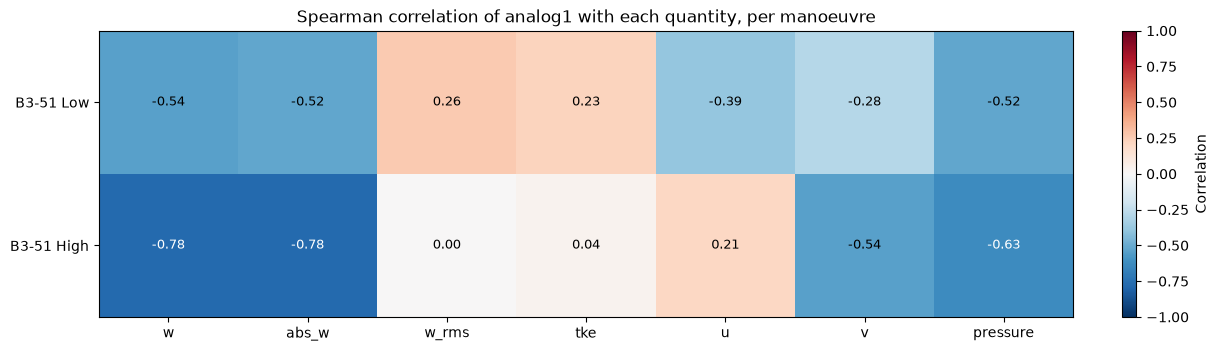

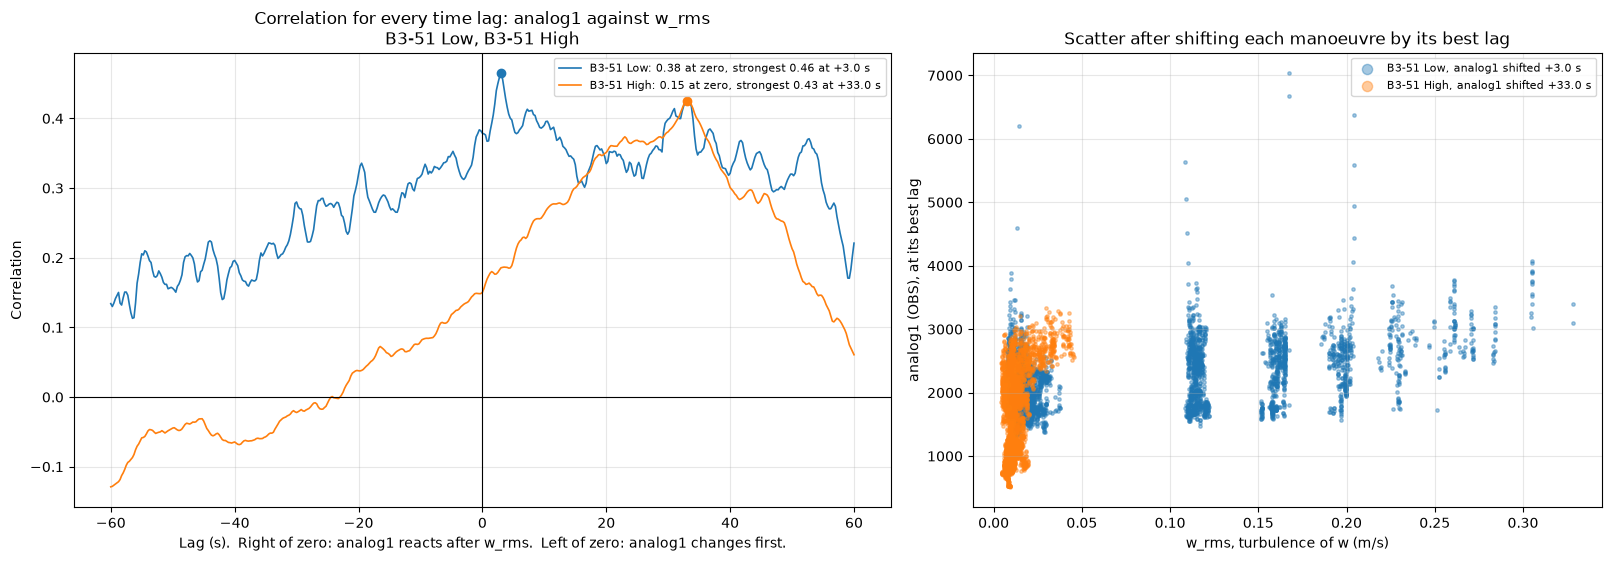

,+0 s,+1 s,+2 s,+5 s,+10 s,+15 s,+20 s,+30 s,+45 s,+60 s,best_lag_s,r_at_best_lag
analog1 vs w_rms,,,,,,,,,,,,
B3-51 Low,0.379,0.368,0.421,0.388,0.390,0.334,0.335,0.399,0.348,0.221,3.0,0.465
B3-51 High,0.150,0.174,0.176,0.196,0.263,0.300,0.351,0.381,0.283,0.061,33.0,0.426


,n,n_independent,pearson_r,ci_low,ci_high,p_value,spearman,r_squared,slope,covariance,best_lag_s,r_at_best_lag
analog1 vs w_rms,,,,,,,,,,,,
B3-51 Low,3841.0,103.0,0.3787,0.2003,0.5328,0.0001,0.2621,0.1434,2447.4599,14.4797,3.0,0.4647
B3-51 High,3841.0,23.0,0.1503,-0.2829,0.5326,0.4974,0.0021,0.0226,15308.7695,0.6160,33.0,0.4256


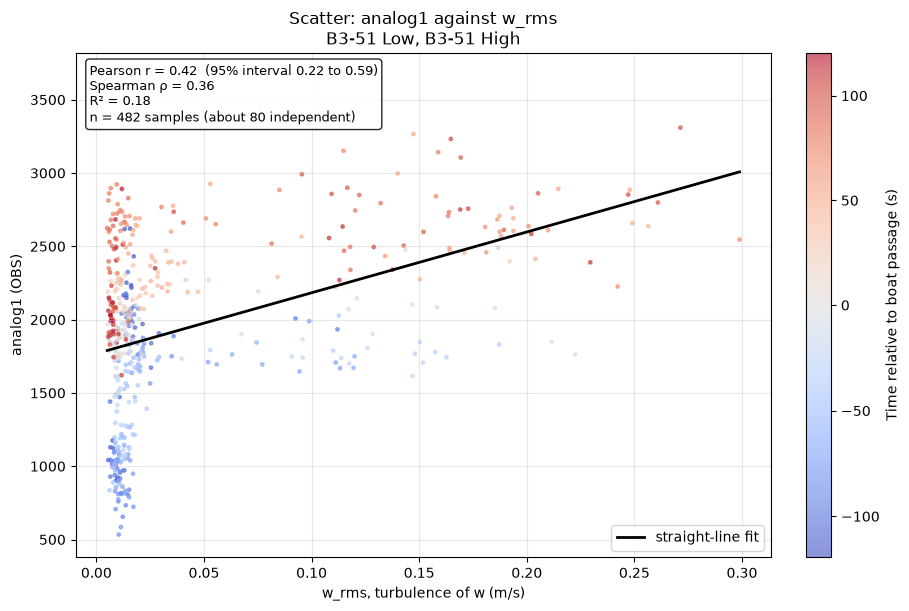

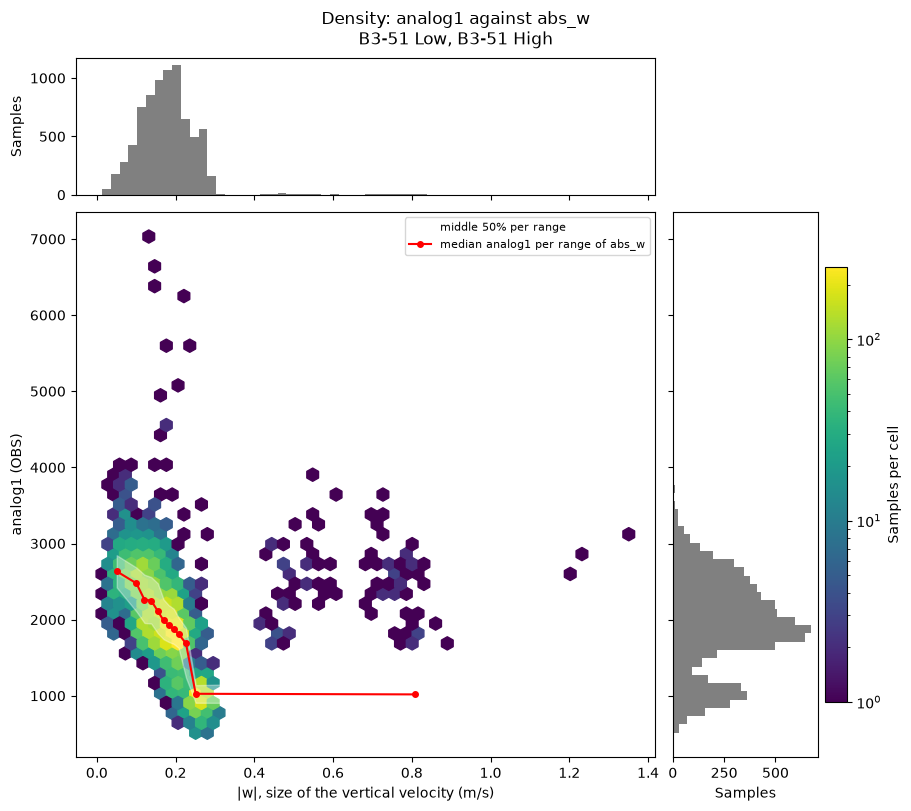

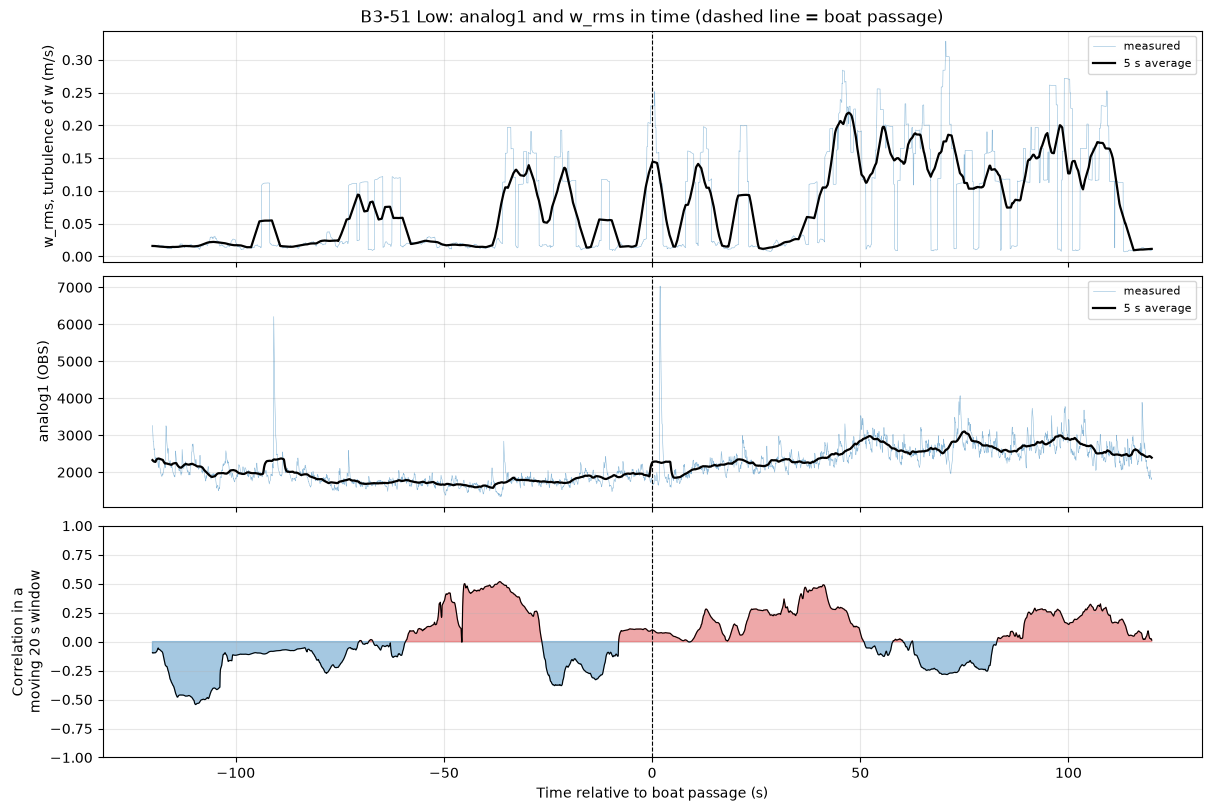

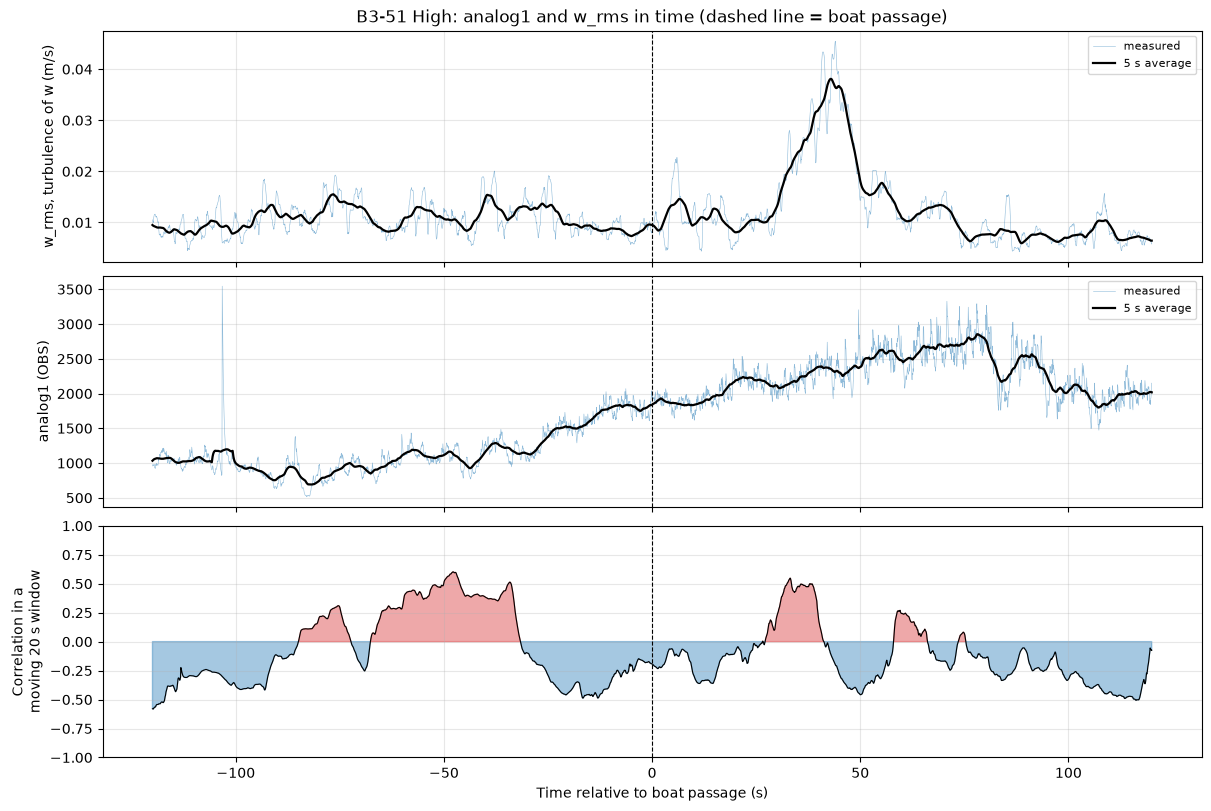

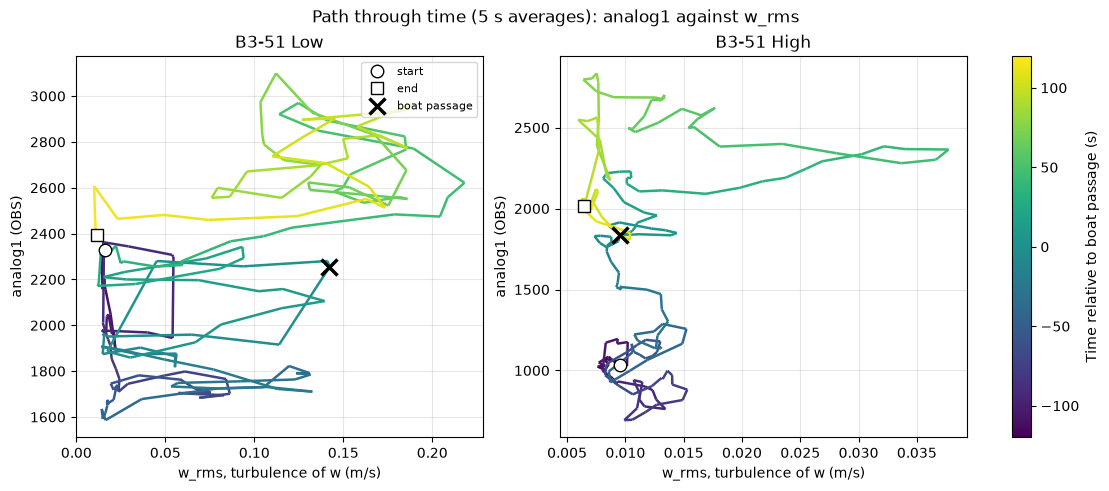

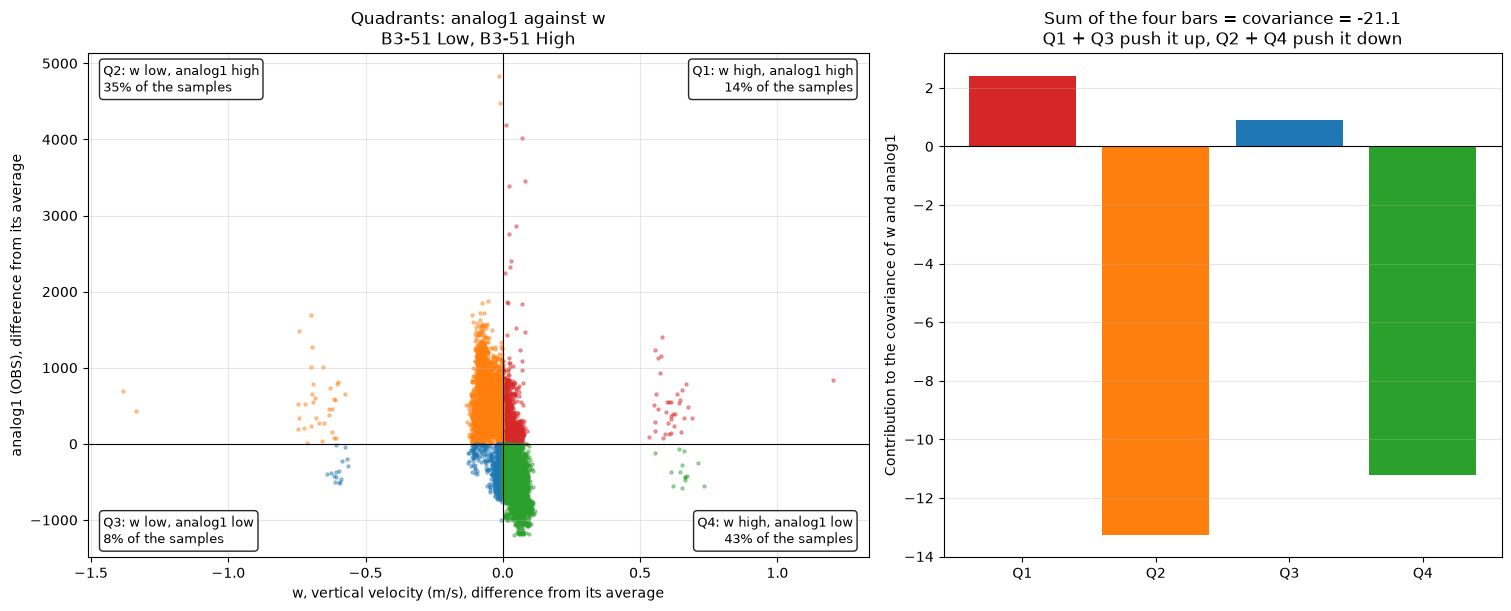

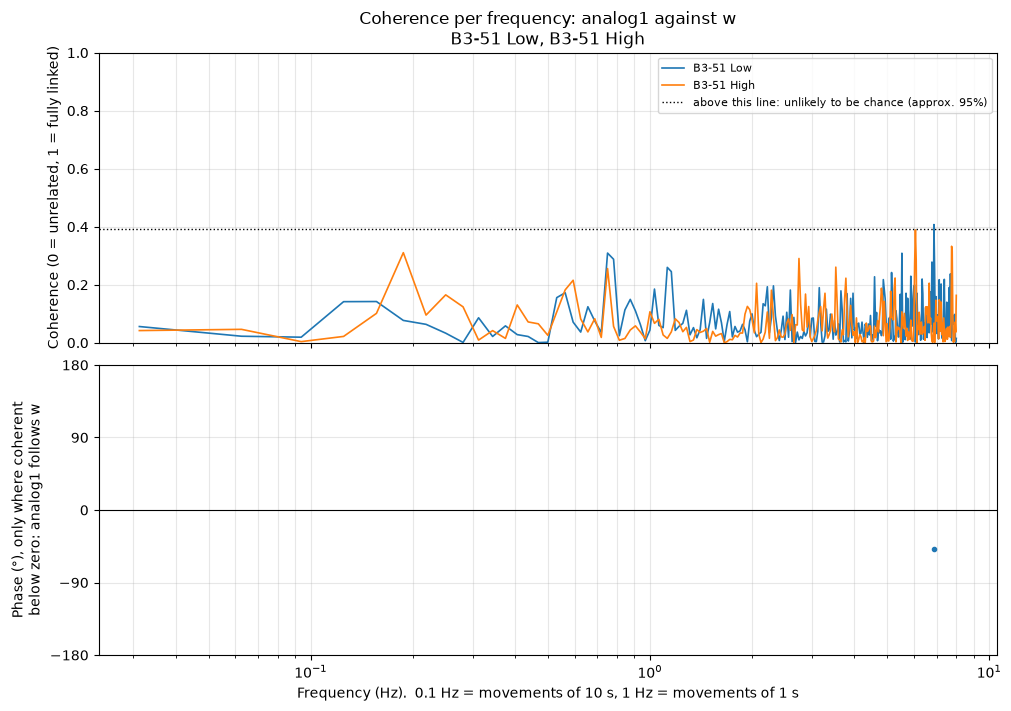

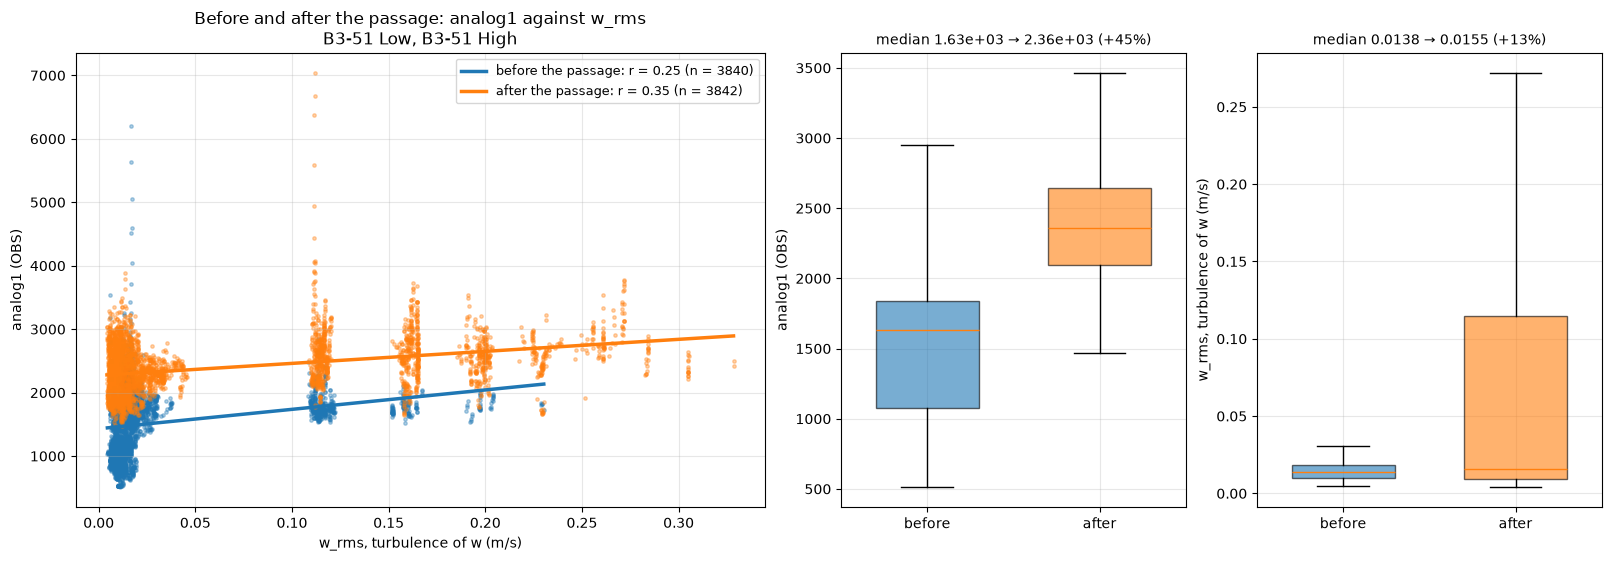

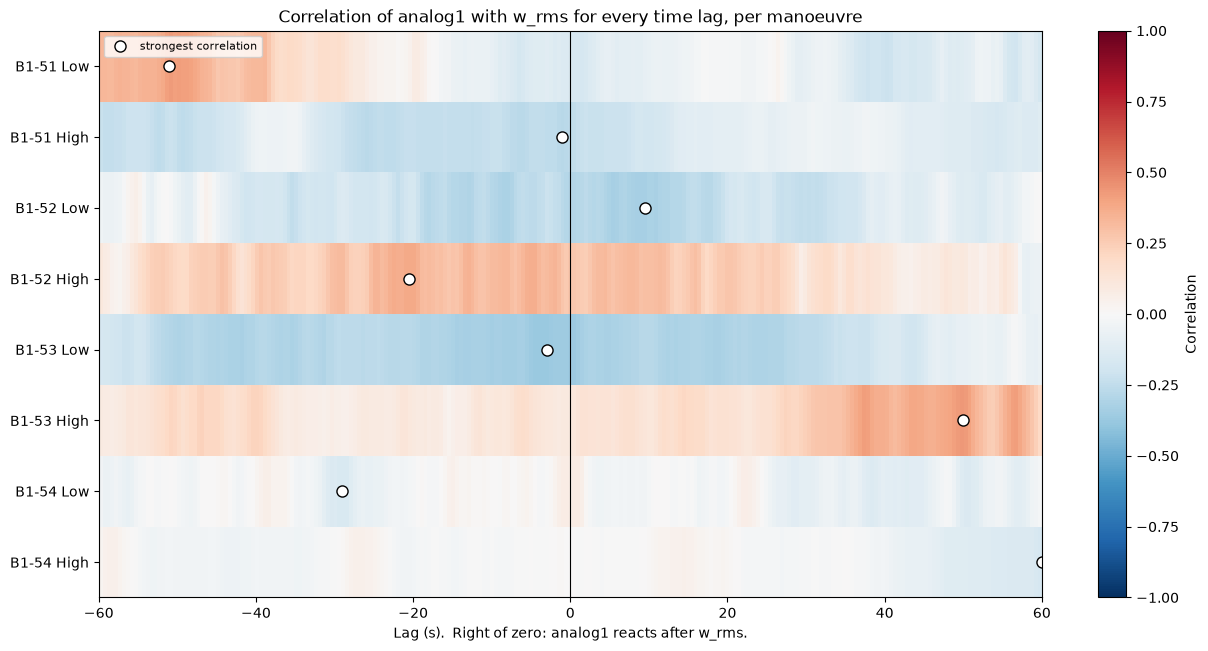

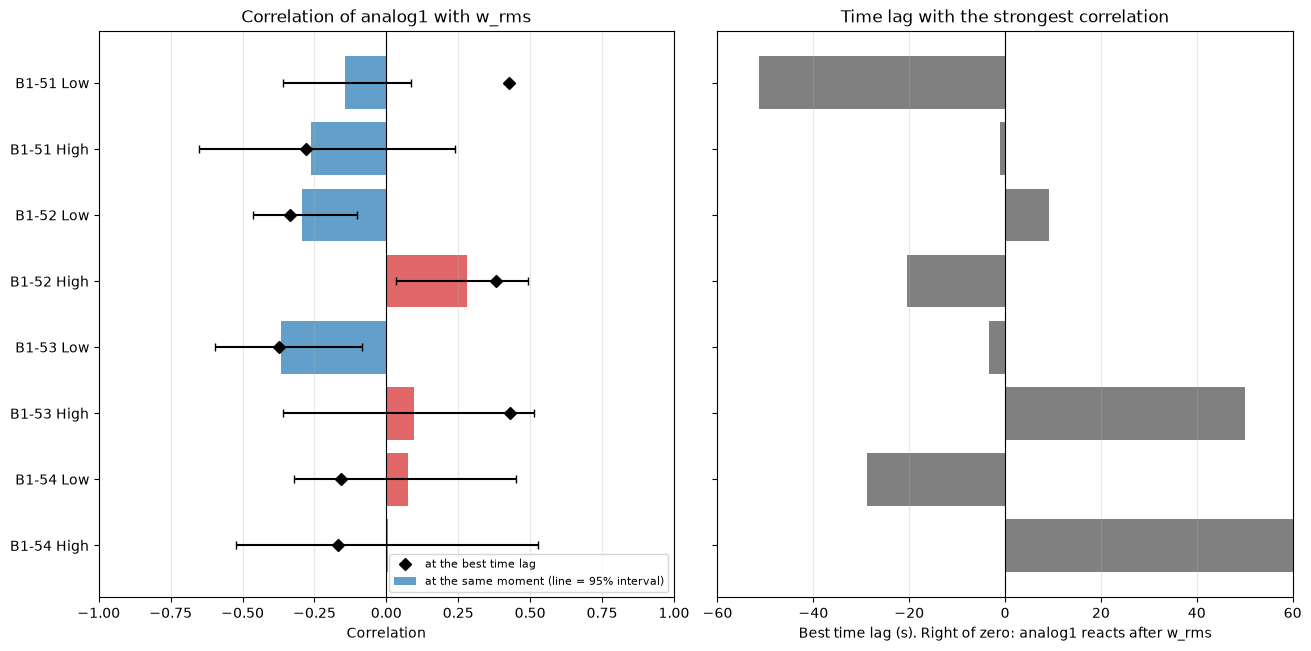

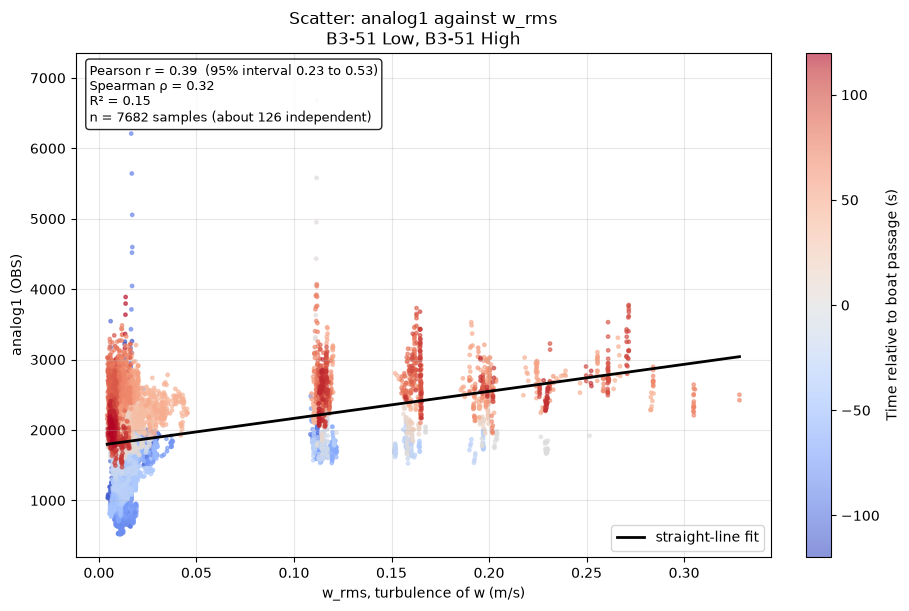

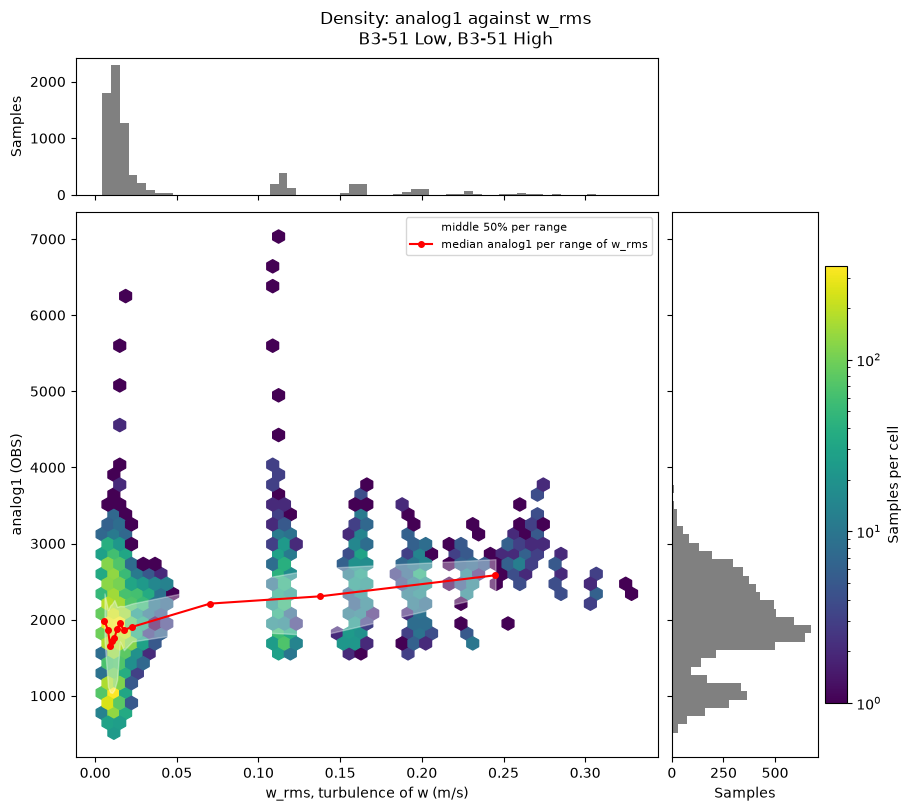

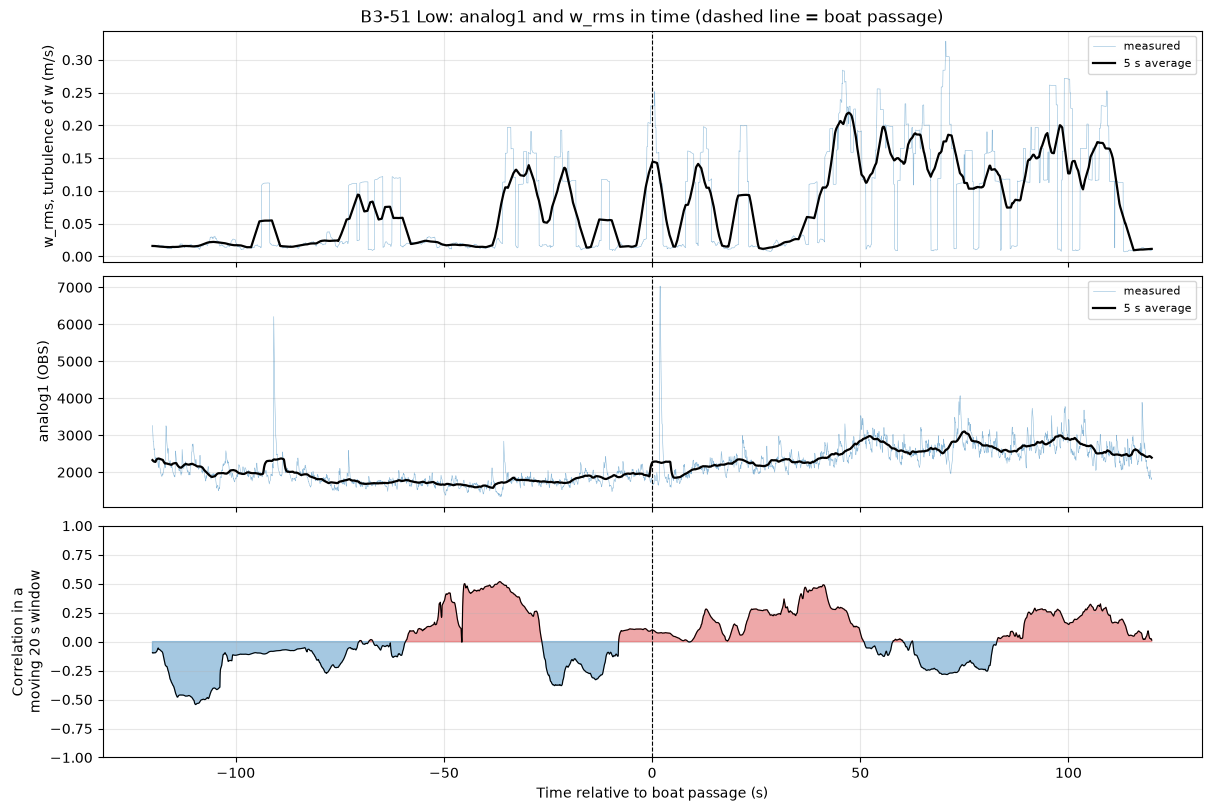

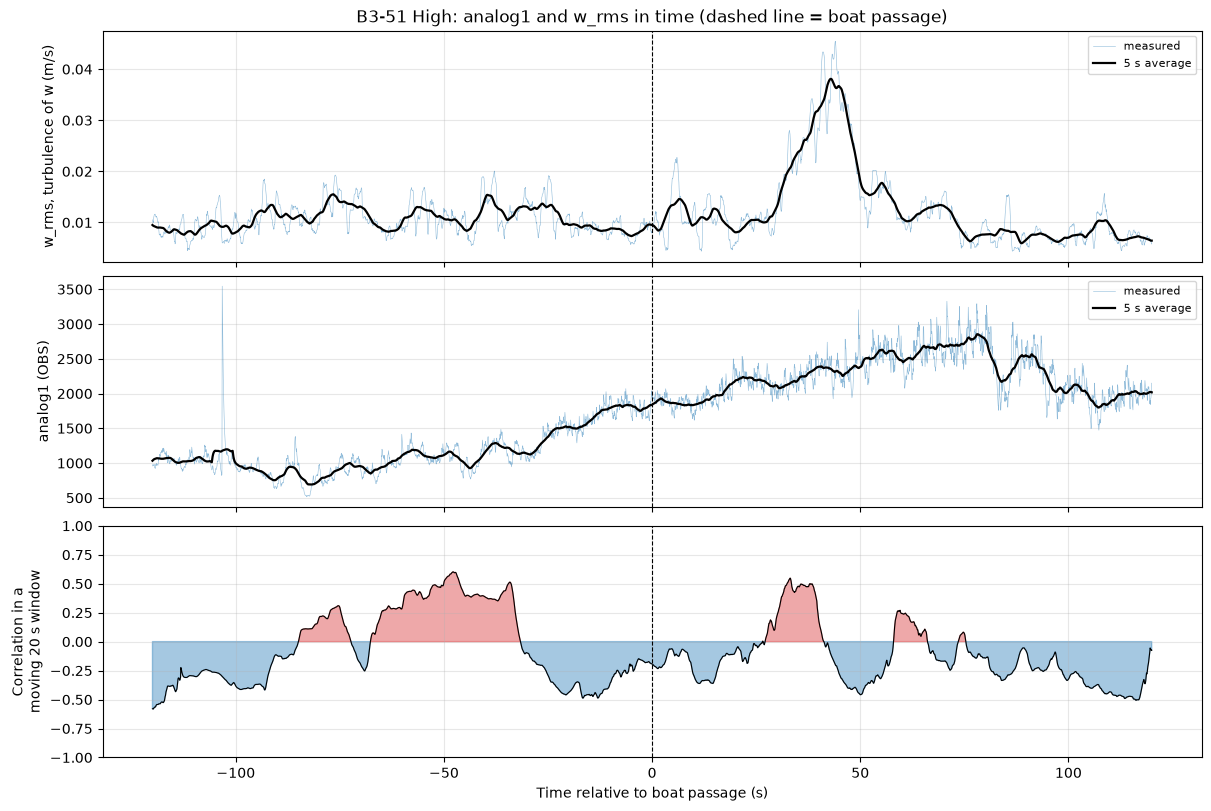

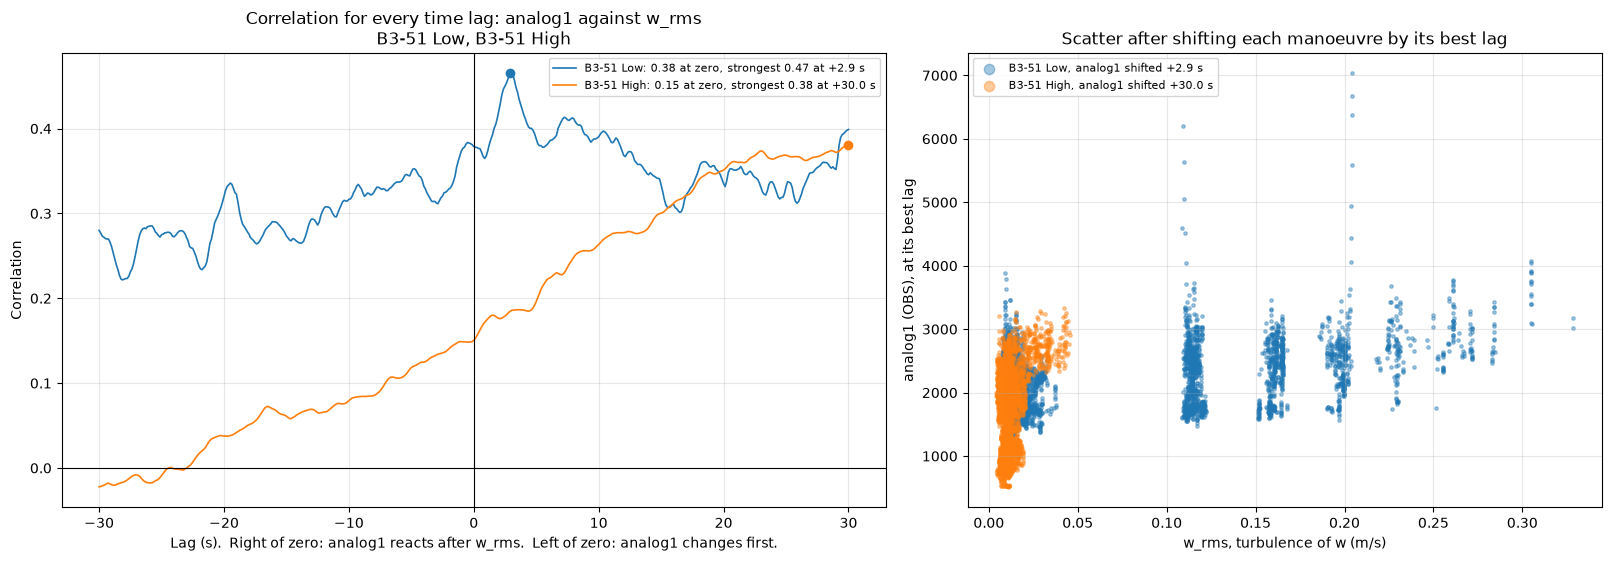

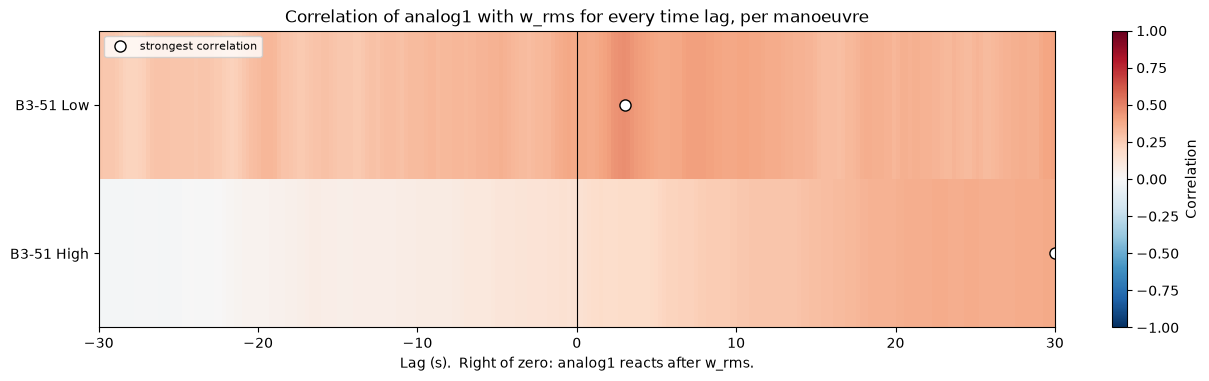

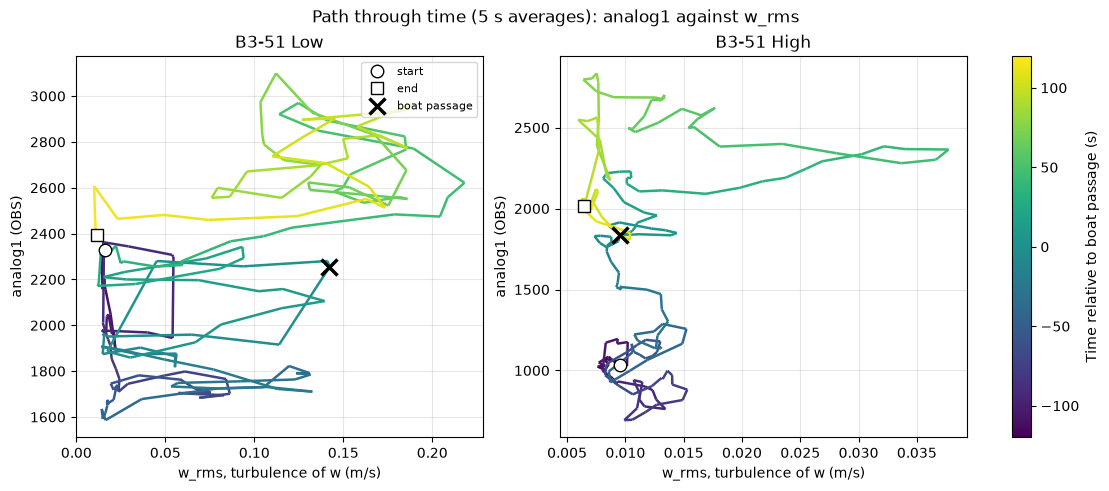

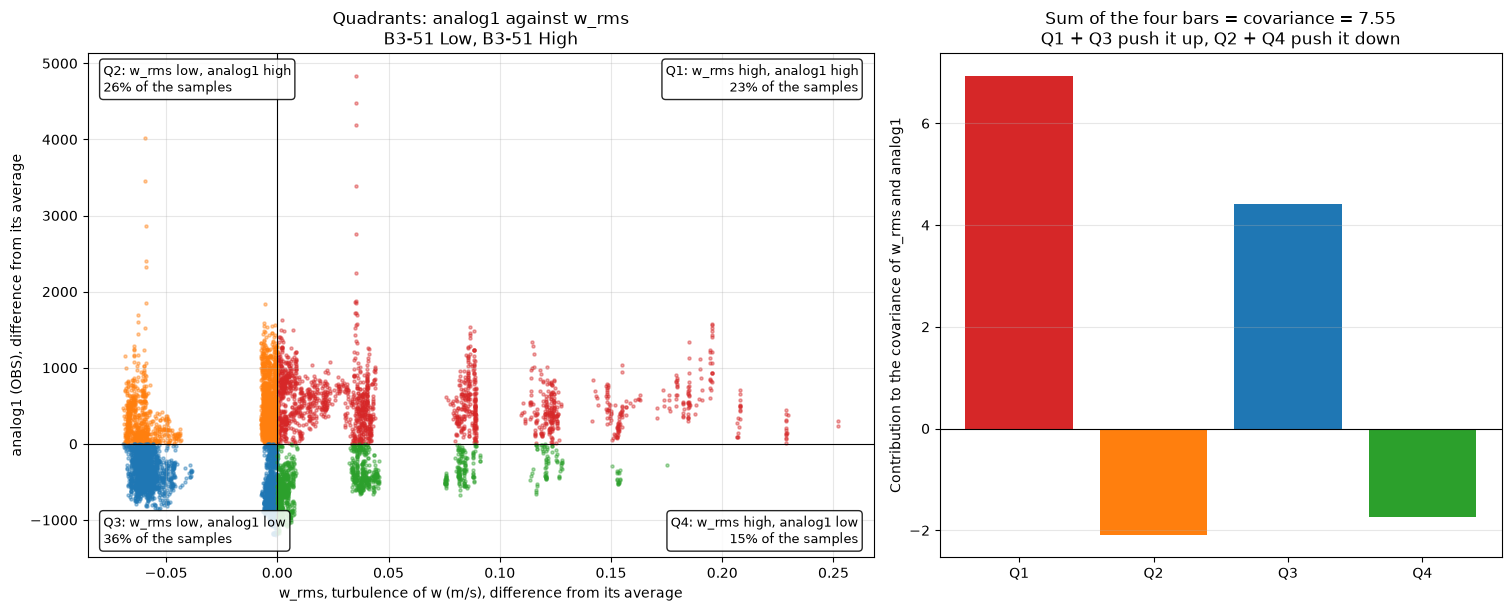

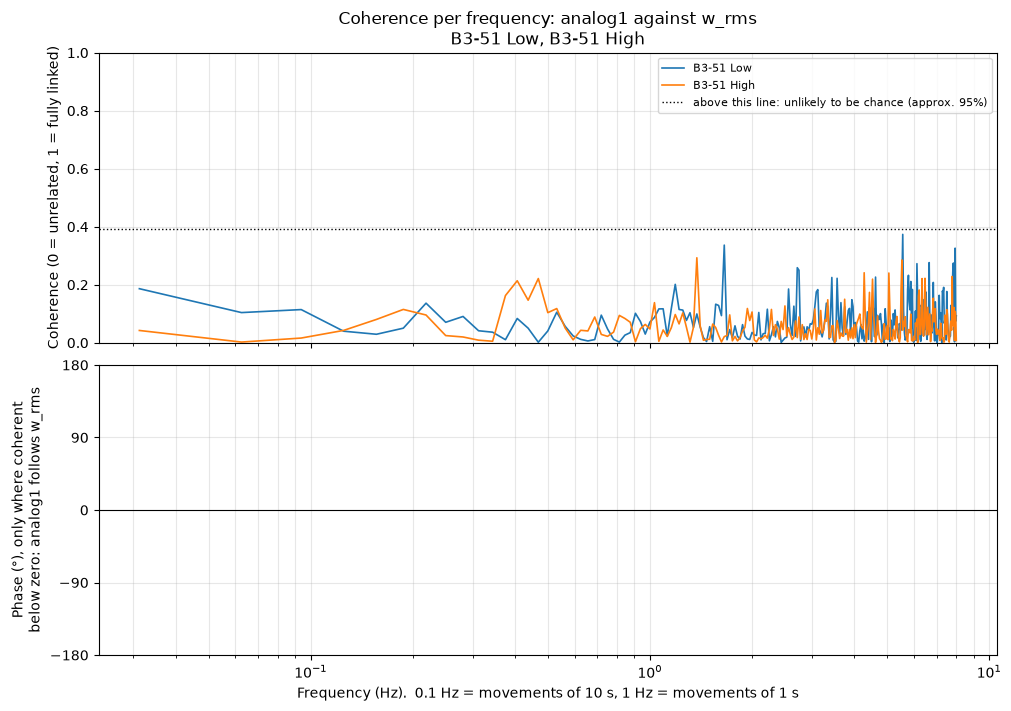

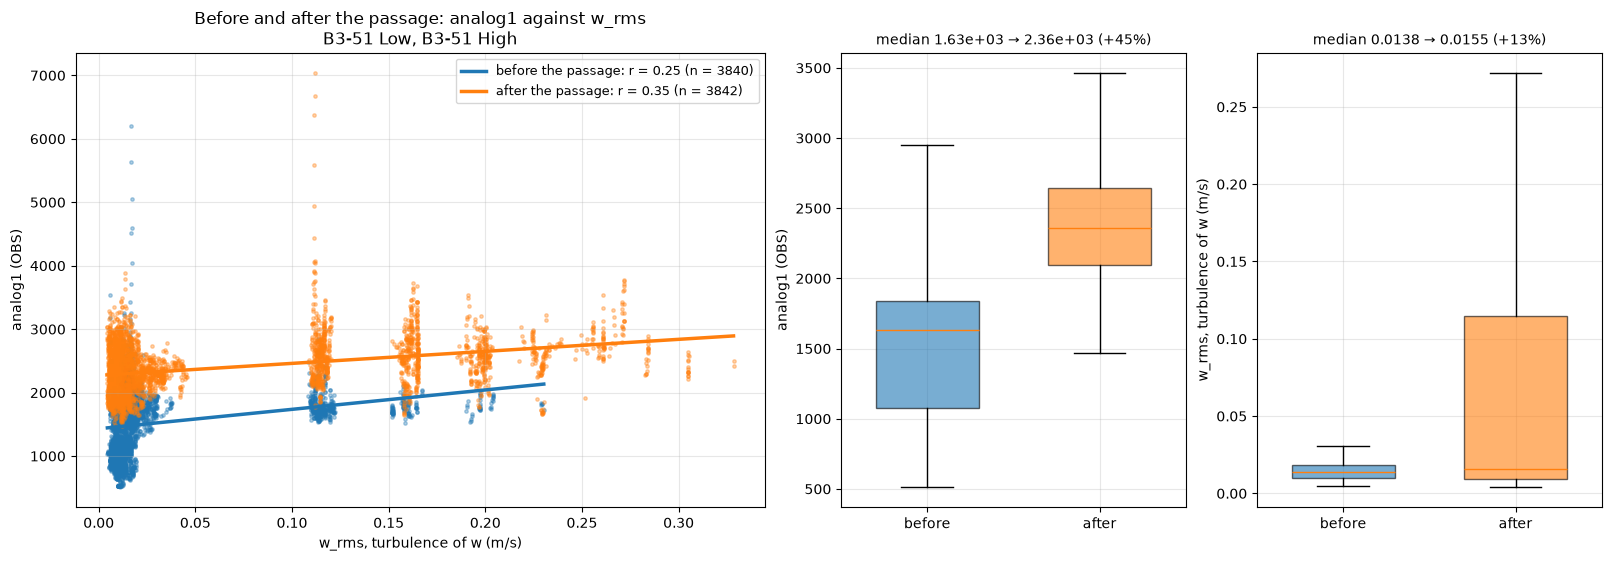

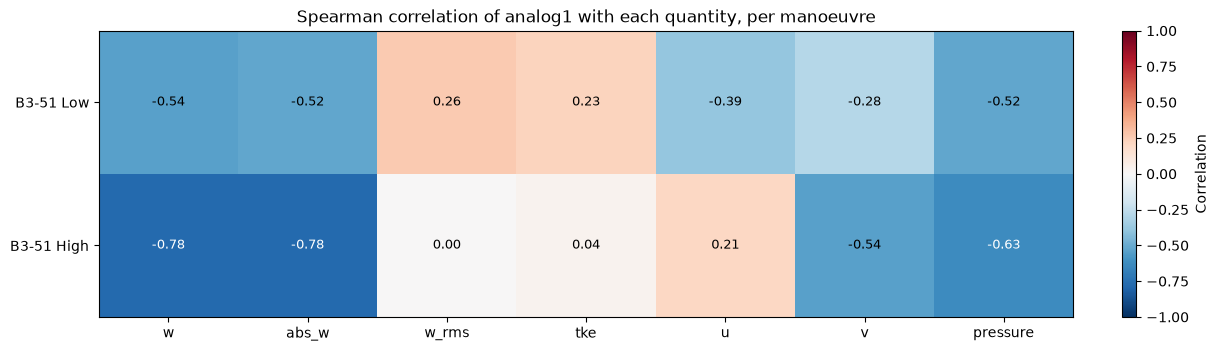

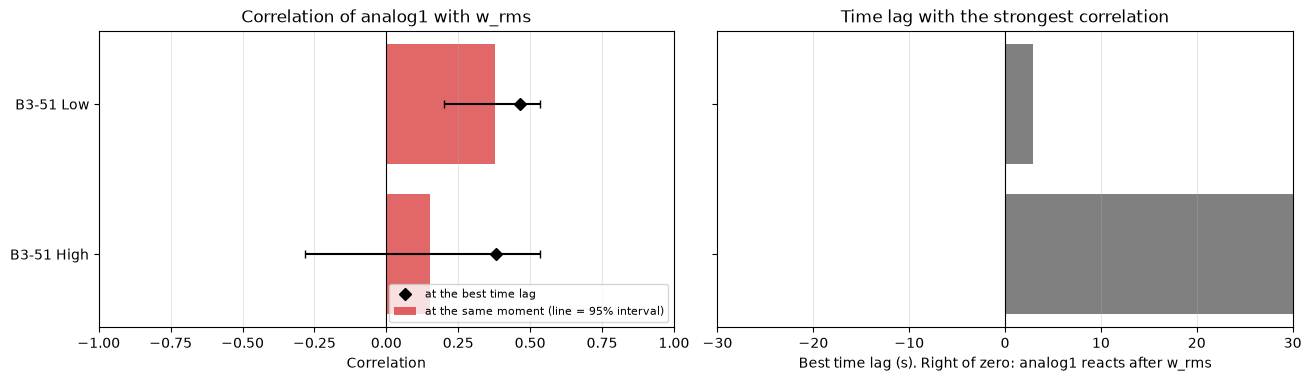

In [18]:
MANOEUVRE = "B3-51"     # one id, a list of ids, or a whole type such as "B1"

# 1. Which velocity quantity relates best to the OBS signal?
plot_relation(MANOEUVRE, kind="heatmap")

# 2. What time lag is there? Correlation for different lags, as a plot and as a table.
plot_relation(MANOEUVRE, kind="lag", x="w_rms", max_lag=60)
display(lag_table(MANOEUVRE, x="w_rms", lags=(0, 1, 2, 5, 10, 15, 20, 30, 45, 60)))

# 3. The numbers per manoeuvre
display(relation_stats(MANOEUVRE, x="w_rms", max_lag=60))

# More options (remove the # to use one)
#lot_relation(MANOEUVRE, kind="scatter")                          # analog1 against w
plot_relation(MANOEUVRE, kind="scatter", x="w_rms", avg=1)        # against turbulence, 1 s averages
plot_relation(MANOEUVRE, kind="density", x="abs_w")
plot_relation(MANOEUVRE, kind="timeseries", x="w_rms")
plot_relation(MANOEUVRE, kind="phase", x="w_rms", smooth=5)
plot_relation(MANOEUVRE, kind="quadrant")
plot_relation(MANOEUVRE, kind="coherence")
plot_relation(MANOEUVRE, kind="beforeafter", x="w_rms")
plot_relation("B1", kind="lagmap", x="w_rms", max_lag=60)         # every B1 manoeuvre
plot_relation("B1", kind="summary", x="w_rms", max_lag=60)
plot_relation(MANOEUVRE, kind="all", x="w_rms")                   # every plot